In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
PERFORMANCE_EXPORT_FOLDER = "/Users/duongtuanhoang/simulated-desktop/devzone/iot-research/performance"
CONFIG_FILE = "config.json"
PERFORMANCE_FILE = "performance.csv"
DETAIL_PERFORMANCE_FILE = "detail_performance.csv"

In [3]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"

In [4]:
MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
device_mapping_1 = pd.read_csv(MAPPING_LIST_1)
device_dict_1 = (
    device_mapping_1
    .set_index("mac_address")
    .drop(columns=["mac_address"], errors="ignore")
    .to_dict(orient="index")
)
device_dict_1

{'d0:52:a8:00:67:5e': {'device_name': 'Smart Things',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'hub',
  'vendor': 'Samsung SmartThings'},
 '44:65:0d:56:cc:d3': {'device_name': 'Amazon Echo',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'smart speaker',
  'vendor': 'Amazon'},
 '70:ee:50:18:34:43': {'device_name': 'Netatmo Welcome',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Netatmo'},
 'f4:f2:6d:93:51:f1': {'device_name': 'TP-Link Day Night Cloud camera',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'TP-Link'},
 '00:16:6c:ab:6b:88': {'device_name': 'Samsung SmartCam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Samsung'},
 '30:8c:fb:2f:e4:b2': {'device_name': 'Dropcam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Dropcam'},
 '00:62:6e:51:27:2e': {'device_name': 'Insteon Camera Wired',
  'ip_address': 

In [5]:
folders = [PERFORMANCE_EXPORT_FOLDER + "/" + file.name for file in Path(PERFORMANCE_EXPORT_FOLDER).iterdir()]
folders

['/Users/duongtuanhoang/simulated-desktop/devzone/iot-research/performance/outgoing_total_bytes_incoming_packet_count_incoming_total_bytes__drop_router__nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera',
 '/Users/duongtuanhoang/simulated-desktop/devzone/iot-research/performance/outgoing_packet_count_outgoing_total_bytes_incoming_packet_count_aggregated_packet_count__no_dropping__nonIot-vs-iot',
 '/Users/duongtuanhoang/simulated-desktop/devzone/iot-research/performance/outgoing_packet_count_incoming_packet_count_aggregated_packet_count_aggregated_total_bytes_idle_time__drop_router__nonIot-vs-iot-vs-iotCamera',
 '/Users/duongtuanhoang/simulated-desktop/devzone/iot-research/performance/outgoing_total_bytes_incoming_packet_count_incoming_total_bytes_idle_time__drop_router_and_camera__nonIot-vs-iot-vs-iotHealthCare',
 '/Users/duongtuanhoang/simulated-desktop/devzone/iot-research/performance/outgoing_packet_count_outgoing_total_bytes_incoming_packet_count_aggregated_total_bytes_idle_time__drop_ro

In [6]:
# Load all performance
all_perfs = {}
for folder in folders:
    key = folder.split("/")[-1]
    if key in all_perfs:
        raise ValueError("Duplicated config")
    
    config = {}
    config_file = f"{folder}/{CONFIG_FILE}"
    metric_file = f"{folder}/{PERFORMANCE_FILE}"
    detail_file = f"{folder}/{DETAIL_PERFORMANCE_FILE}"
    with open(config_file, "r") as f:
        config = json.load(f)
    metric_df = pd.read_csv(metric_file)
    detail_file = pd.read_csv(detail_file)
    config["performance"] = metric_df
    config["detail_performance"] = detail_file
    all_perfs[key] = config

In [7]:
all_perfs

{'outgoing_total_bytes_incoming_packet_count_incoming_total_bytes__drop_router__nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera': {'class_labels': [1,
   2,
   3,
   4],
  'dropping_strategy': 'drop_router',
  'feature_combination': ['outgoing_total_bytes',
   'incoming_packet_count',
   'incoming_total_bytes'],
  'labeling_strategy': 'nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera',
  'average_across_all_windows': 0.9419259259259257,
  'performance':      accuracy  device_count  correct_count  misclassified_count  \
  0    0.888889            27             24                    3   
  1    0.888889            27             24                    3   
  2    0.888889            27             24                    3   
  3    0.851852            27             23                    4   
  4    0.851852            27             23                    4   
  ..        ...           ...            ...                  ...   
  245  1.000000            27             27                    0   
 

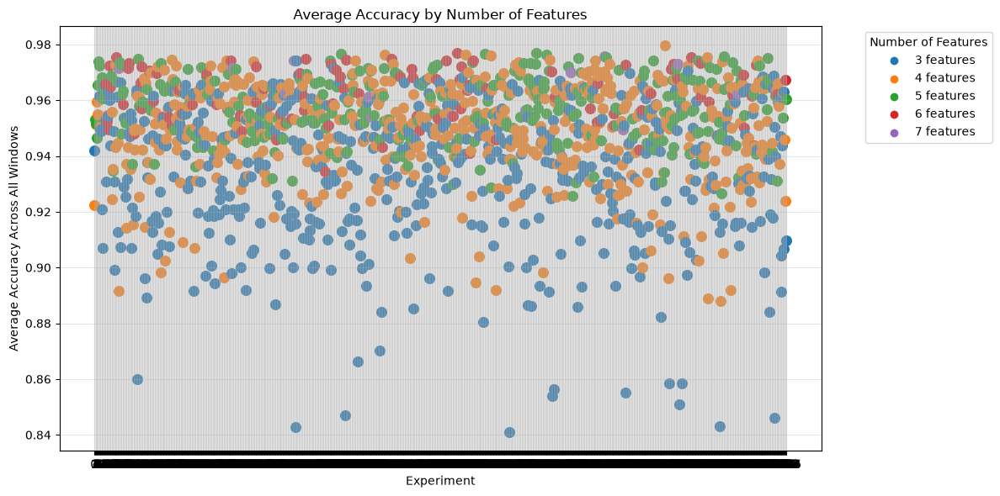

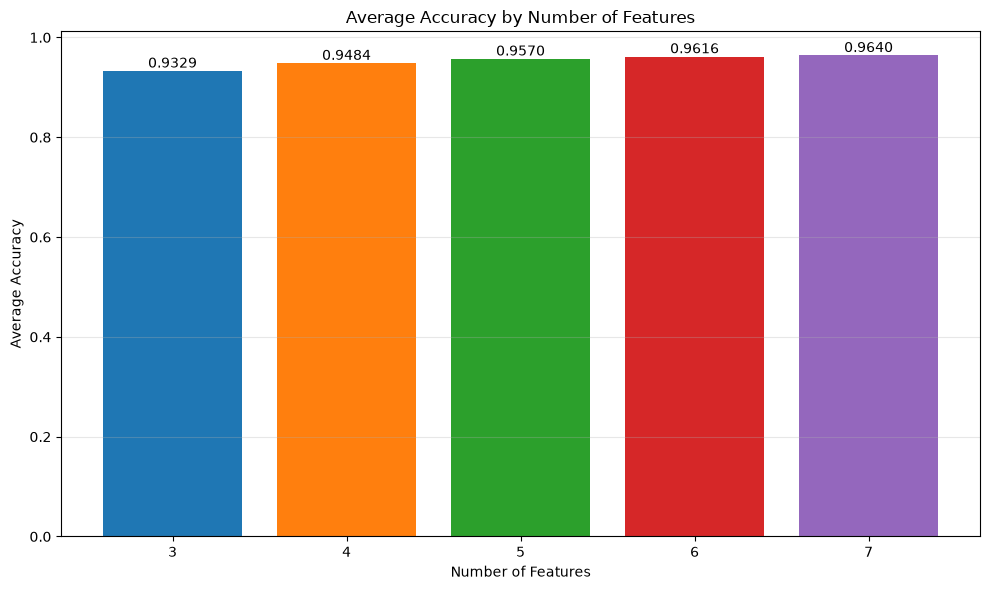

   num_features  accuracy
0             3  0.932892
1             4  0.948358
2             5  0.956980
3             6  0.961610
4             7  0.963993


In [8]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
num_features = []
accuracies = []

for result in all_perfs.values():
    # if result["dropping_strategy"] == "drop_router" and result["labeling_strategy"] == "nonIot-vs-iot":
    num_features.append(len(result["feature_combination"]))
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each feature count
# --------------------------------
unique_num_features = sorted(set(num_features))

color_map = {
    n: plt.cm.tab10(i % 10)
    for i, n in enumerate(unique_num_features)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (n, accuracy) in enumerate(
    zip(num_features, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[n],
        s=70
    )

# Legend
for n in unique_num_features:
    plt.scatter(
        [],
        [],
        color=color_map[n],
        label=f"{n} features"
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Number of Features")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Number of Features",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy by number of features
# ==========================================

plot_df = pd.DataFrame({
    "num_features": num_features,
    "accuracy": accuracies
})

avg_by_num_features = (
    plot_df
    .groupby("num_features", as_index=False)["accuracy"]
    .mean()
    .sort_values("num_features")
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_num_features["num_features"].astype(str),
    avg_by_num_features["accuracy"],
    color=[
        color_map[n]
        for n in avg_by_num_features["num_features"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_num_features["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Number of Features")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Number of Features")

plt.grid(axis="y", alpha=0.3)

# Leave space for labels above bars
plt.ylim(
    0,
    avg_by_num_features["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Display exact values
print(avg_by_num_features)

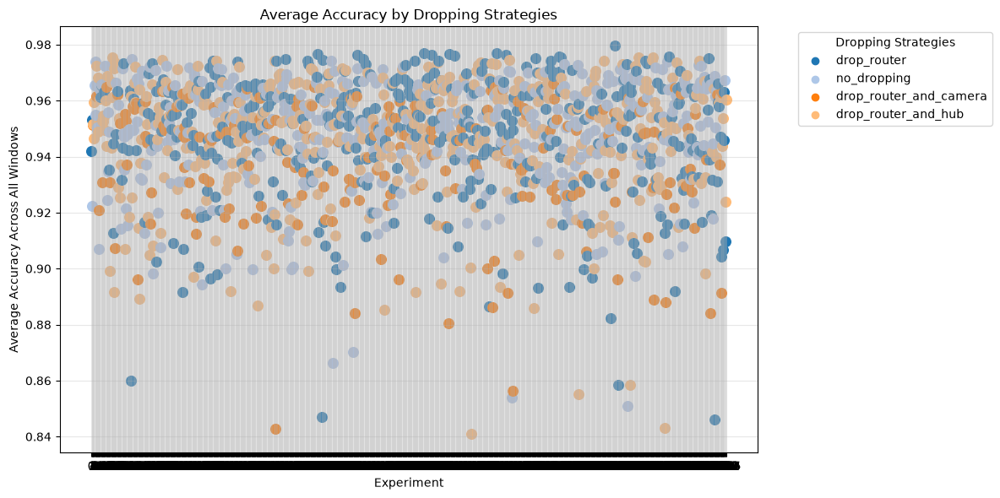

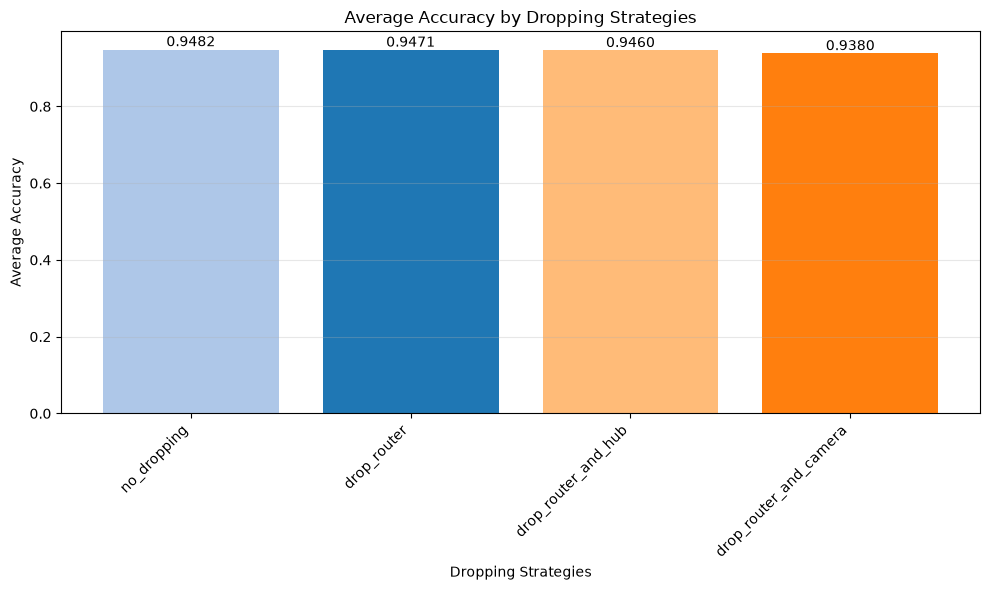

        dropping_strategy  accuracy
3             no_dropping  0.948221
0             drop_router  0.947137
2     drop_router_and_hub  0.946002
1  drop_router_and_camera  0.937979


In [9]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
dropping_strategies = []
accuracies = []

for result in all_perfs.values():
    dropping_strategies.append(result["dropping_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_dropping_strategies = list(dict.fromkeys(dropping_strategies))

color_map = {
    dropping_strategy: plt.cm.tab20(i % 20)
    for i, dropping_strategy in enumerate(unique_dropping_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (dropping_strategy, accuracy) in enumerate(
    zip(dropping_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[dropping_strategy],
        s=70
    )

# Legend
for dropping_strategy in unique_dropping_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[dropping_strategy],
        label=dropping_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Dropping Strategies",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Dropping Strategies
# ==========================================

plot_df = pd.DataFrame({
    "dropping_strategy": dropping_strategies,
    "accuracy": accuracies
})

avg_by_dropping_strategy = (
    plot_df
    .groupby("dropping_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_dropping_strategy["dropping_strategy"],
    avg_by_dropping_strategy["accuracy"],
    color=[
        color_map[dropping_strategy]
        for dropping_strategy in avg_by_dropping_strategy["dropping_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_dropping_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Dropping Strategies")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_dropping_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_dropping_strategy)

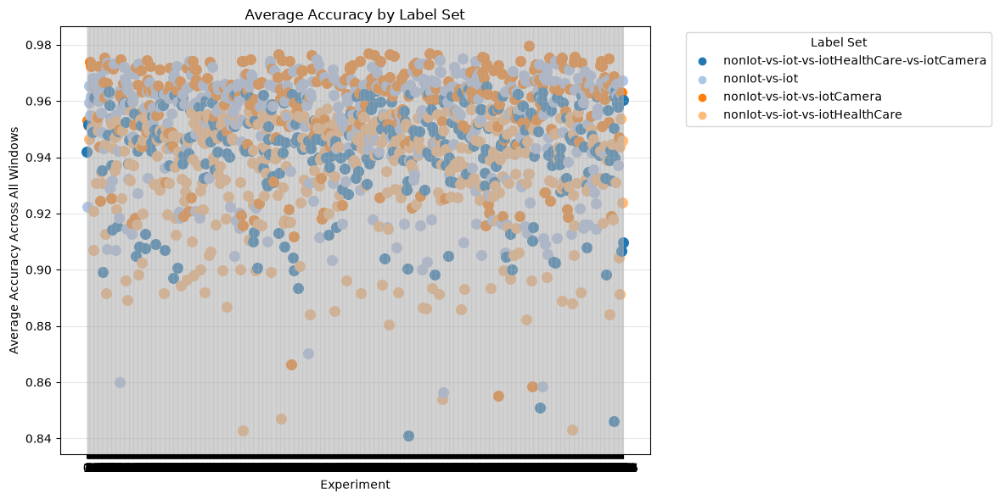

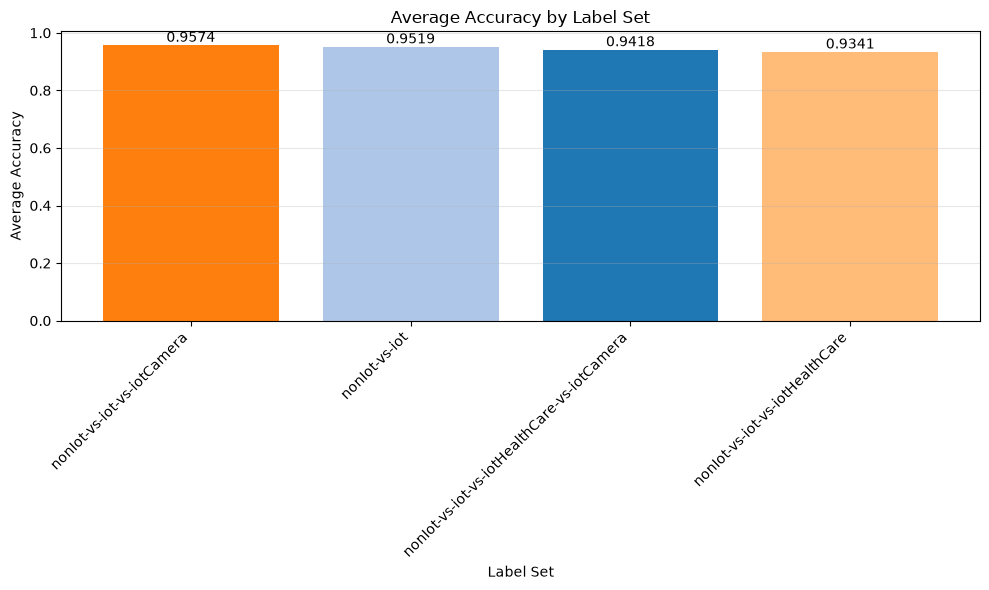

                             labeling_strategy  accuracy
1                   nonIot-vs-iot-vs-iotCamera  0.957362
0                                nonIot-vs-iot  0.951893
3  nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera  0.941844
2               nonIot-vs-iot-vs-iotHealthCare  0.934052


In [10]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
labeling_strategies = []
accuracies = []

for result in all_perfs.values():
    labeling_strategies.append(result["labeling_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_labeling_strategies = list(dict.fromkeys(labeling_strategies))

color_map = {
    labeling_strategy: plt.cm.tab20(i % 20)
    for i, labeling_strategy in enumerate(unique_labeling_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (labeling_strategy, accuracy) in enumerate(
    zip(labeling_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[labeling_strategy],
        s=70
    )

# Legend
for labeling_strategy in unique_labeling_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[labeling_strategy],
        label=labeling_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Label Set")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Label Set",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Label Set
# ==========================================

plot_df = pd.DataFrame({
    "labeling_strategy": labeling_strategies,
    "accuracy": accuracies
})

avg_by_labeling_strategy = (
    plot_df
    .groupby("labeling_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_labeling_strategy["labeling_strategy"],
    avg_by_labeling_strategy["accuracy"],
    color=[
        color_map[labeling_strategy]
        for labeling_strategy in avg_by_labeling_strategy["labeling_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_labeling_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Label Set")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Label Set")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_labeling_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_labeling_strategy)

# Comment on all hyperparameters
- With regard to different dropping_strategy and labeling_strategy, I don't see much improvement.
- The features set say otherwise.
    - The set of incoming features demonstrate better prediction compare to outgoing features. 
        - <mark>Explore why?</mark>
    - Both set together behave better compare to incoming features. The accuracy increase a bit, but the variance decrease -> stable prediction.
        - <mark>Explore why?</mark>
    

- So nonIot-vs-iot-vs-iotCamera and nonIot-vs-iot are two labeling strategies that have higher accuracies

- IPhone (d0:a6:37:df:a1:e1) is usually the one that get misclassified a lot. 

- Mixing good config together
- Add all_data together
- Consider idle time to be last active (both outgoing and incoming)
- Analyze the extreme worst point of data

# Analysis on September 20th
- Apparently 3 features is behaving really bad compared to the other.
- `drop_router_and_camera` is giving the worst result (93%). Let's drop the 3 features out and see how it behaves.
## 1.1 - dropping 3 features

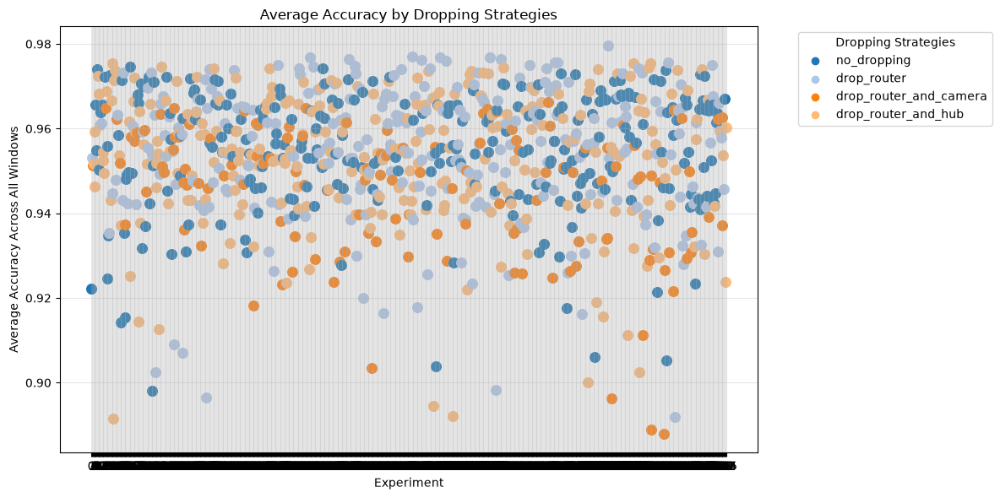

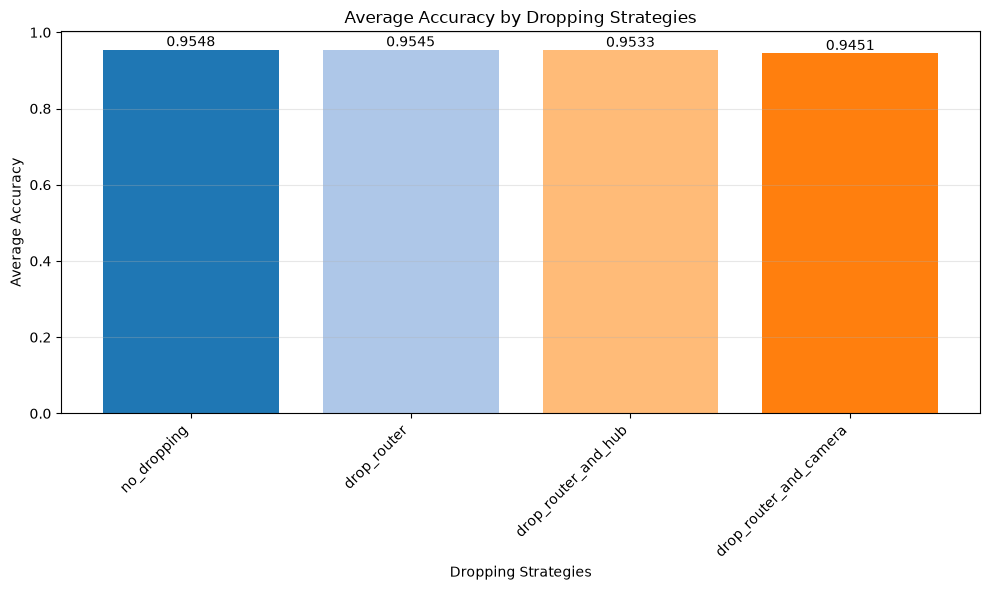

        dropping_strategy  accuracy
3             no_dropping  0.954828
0             drop_router  0.954466
2     drop_router_and_hub  0.953260
1  drop_router_and_camera  0.945060


In [11]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
dropping_strategies = []
accuracies = []

for result in all_perfs.values():
    if len(result["feature_combination"]) > 3:
        dropping_strategies.append(result["dropping_strategy"])
        accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_dropping_strategies = list(dict.fromkeys(dropping_strategies))

color_map = {
    dropping_strategy: plt.cm.tab20(i % 20)
    for i, dropping_strategy in enumerate(unique_dropping_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (dropping_strategy, accuracy) in enumerate(
    zip(dropping_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[dropping_strategy],
        s=70
    )

# Legend
for dropping_strategy in unique_dropping_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[dropping_strategy],
        label=dropping_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Dropping Strategies",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Dropping Strategies
# ==========================================

plot_df = pd.DataFrame({
    "dropping_strategy": dropping_strategies,
    "accuracy": accuracies
})

avg_by_dropping_strategy = (
    plot_df
    .groupby("dropping_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_dropping_strategy["dropping_strategy"],
    avg_by_dropping_strategy["accuracy"],
    color=[
        color_map[dropping_strategy]
        for dropping_strategy in avg_by_dropping_strategy["dropping_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_dropping_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Dropping Strategies")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_dropping_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_dropping_strategy)

- Surprisingly, all dropping strategies increase their accuracy. Let's look at the label set

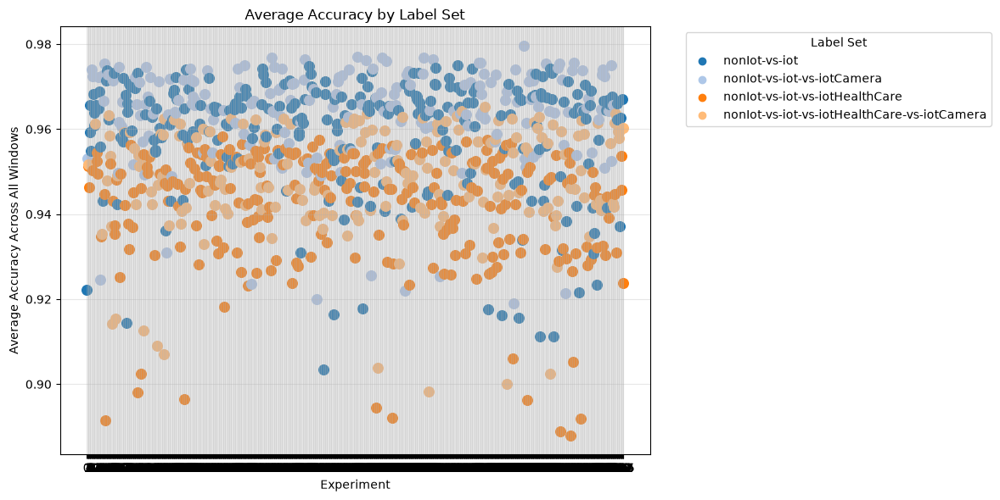

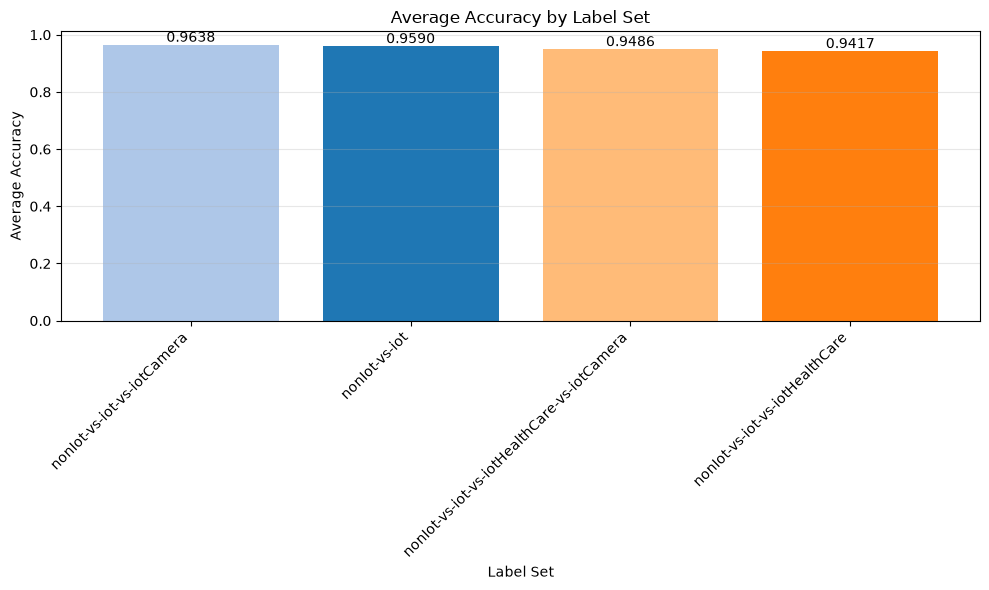

                             labeling_strategy  accuracy
1                   nonIot-vs-iot-vs-iotCamera  0.963783
0                                nonIot-vs-iot  0.959041
3  nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera  0.948635
2               nonIot-vs-iot-vs-iotHealthCare  0.941728


In [12]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
labeling_strategies = []
accuracies = []

for result in all_perfs.values():
    if len(result["feature_combination"]) > 3:
        labeling_strategies.append(result["labeling_strategy"])
        accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_labeling_strategies = list(dict.fromkeys(labeling_strategies))

color_map = {
    labeling_strategy: plt.cm.tab20(i % 20)
    for i, labeling_strategy in enumerate(unique_labeling_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (labeling_strategy, accuracy) in enumerate(
    zip(labeling_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[labeling_strategy],
        s=70
    )

# Legend
for labeling_strategy in unique_labeling_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[labeling_strategy],
        label=labeling_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Label Set")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Label Set",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Label Set
# ==========================================

plot_df = pd.DataFrame({
    "labeling_strategy": labeling_strategies,
    "accuracy": accuracies
})

avg_by_labeling_strategy = (
    plot_df
    .groupby("labeling_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_labeling_strategy["labeling_strategy"],
    avg_by_labeling_strategy["accuracy"],
    color=[
        color_map[labeling_strategy]
        for labeling_strategy in avg_by_labeling_strategy["labeling_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_labeling_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Label Set")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Label Set")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_labeling_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_labeling_strategy)

- There's a clear difference here. The `nonIot-vs-iot-vs-iotHealthCare` did worse compared to the rest. Let's drop that next
### 2.1 - dropping `nonIot-vs-iot-vs-iotHealthCare`

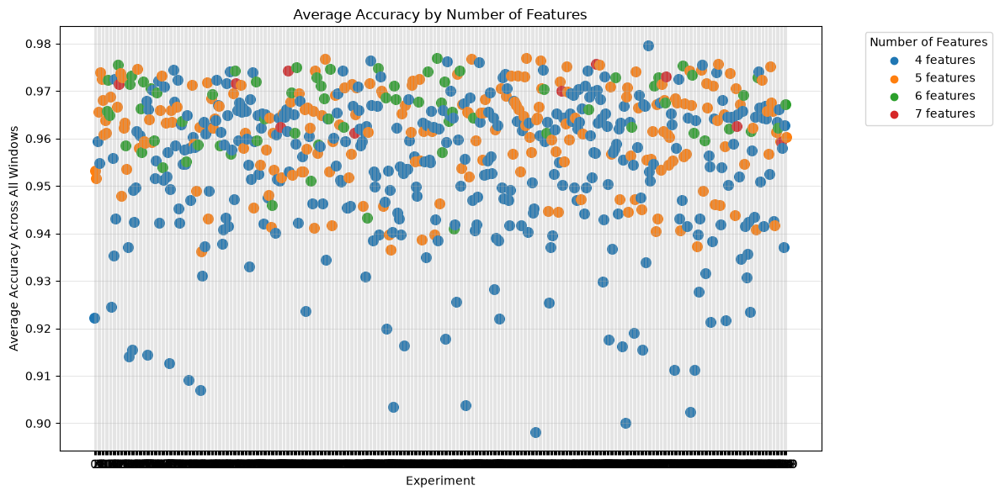

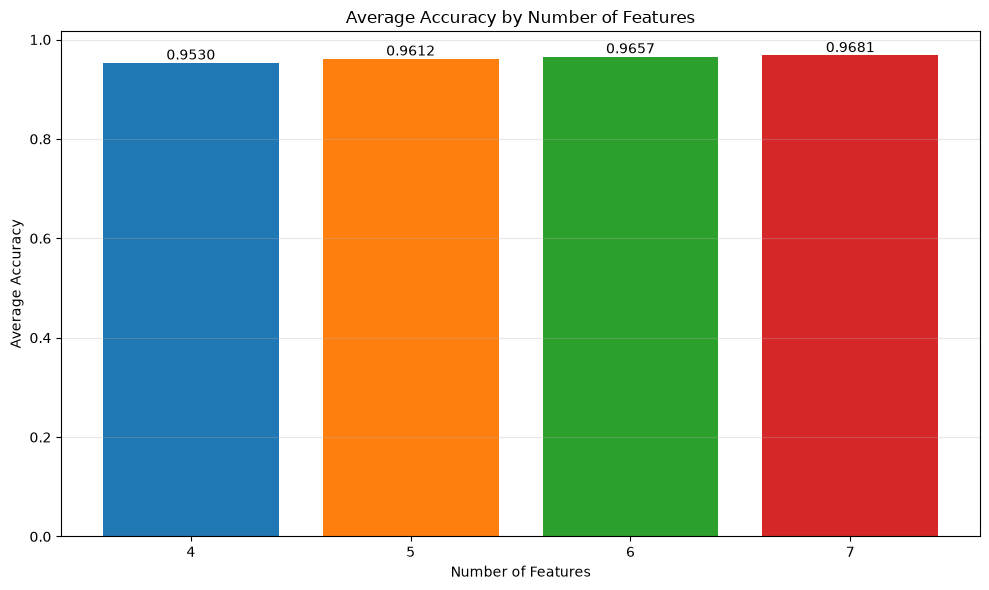

   num_features  accuracy
0             4  0.953047
1             5  0.961207
2             6  0.965677
3             7  0.968143


In [13]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
num_features = []
accuracies = []

for result in all_perfs.values():
    # if result["dropping_strategy"] == "drop_router" and result["labeling_strategy"] == "nonIot-vs-iot":
    if len(result["feature_combination"]) <= 3 or result["labeling_strategy"] == "nonIot-vs-iot-vs-iotHealthCare":
        continue
    num_features.append(len(result["feature_combination"]))
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each feature count
# --------------------------------
unique_num_features = sorted(set(num_features))

color_map = {
    n: plt.cm.tab10(i % 10)
    for i, n in enumerate(unique_num_features)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (n, accuracy) in enumerate(
    zip(num_features, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[n],
        s=70
    )

# Legend
for n in unique_num_features:
    plt.scatter(
        [],
        [],
        color=color_map[n],
        label=f"{n} features"
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Number of Features")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Number of Features",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy by number of features
# ==========================================

plot_df = pd.DataFrame({
    "num_features": num_features,
    "accuracy": accuracies
})

avg_by_num_features = (
    plot_df
    .groupby("num_features", as_index=False)["accuracy"]
    .mean()
    .sort_values("num_features")
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_num_features["num_features"].astype(str),
    avg_by_num_features["accuracy"],
    color=[
        color_map[n]
        for n in avg_by_num_features["num_features"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_num_features["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Number of Features")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Number of Features")

plt.grid(axis="y", alpha=0.3)

# Leave space for labels above bars
plt.ylim(
    0,
    avg_by_num_features["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Display exact values
print(avg_by_num_features)

- Now, the 4 features doesn't work as expected. Let's take a look at dropping strategies

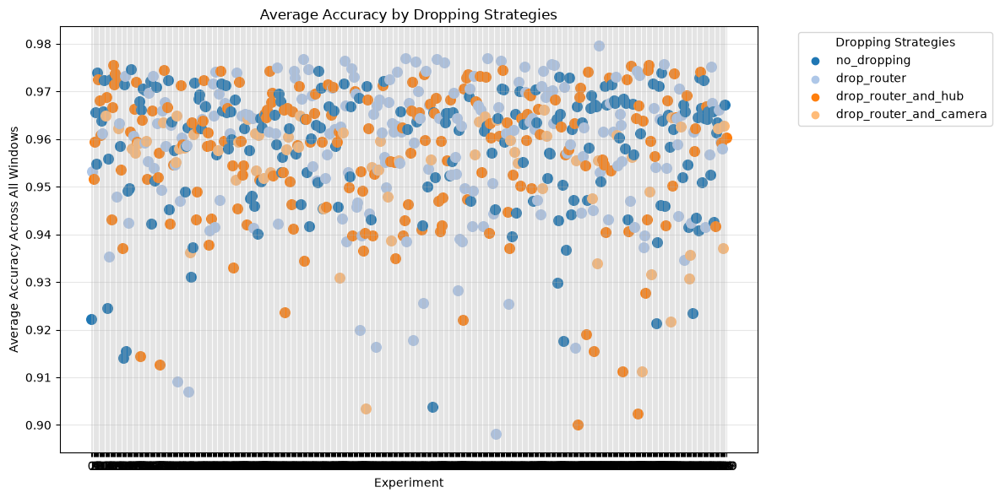

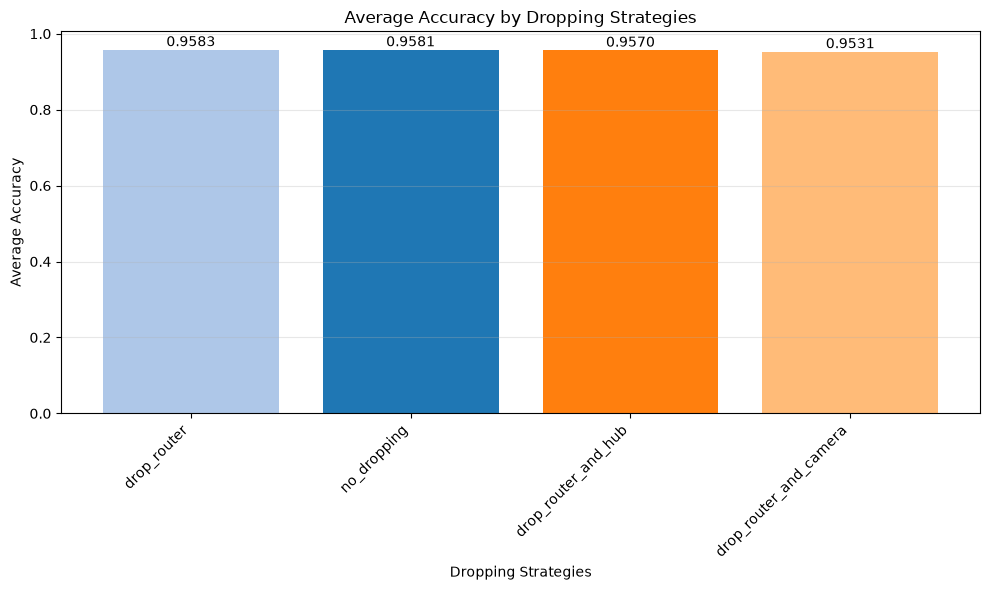

        dropping_strategy  accuracy
0             drop_router  0.958289
3             no_dropping  0.958146
2     drop_router_and_hub  0.957022
1  drop_router_and_camera  0.953051


In [14]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
dropping_strategies = []
accuracies = []

for result in all_perfs.values():
    if len(result["feature_combination"]) <= 3 or result["labeling_strategy"] == "nonIot-vs-iot-vs-iotHealthCare":
        continue
    dropping_strategies.append(result["dropping_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_dropping_strategies = list(dict.fromkeys(dropping_strategies))

color_map = {
    dropping_strategy: plt.cm.tab20(i % 20)
    for i, dropping_strategy in enumerate(unique_dropping_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (dropping_strategy, accuracy) in enumerate(
    zip(dropping_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[dropping_strategy],
        s=70
    )

# Legend
for dropping_strategy in unique_dropping_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[dropping_strategy],
        label=dropping_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Dropping Strategies",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Dropping Strategies
# ==========================================

plot_df = pd.DataFrame({
    "dropping_strategy": dropping_strategies,
    "accuracy": accuracies
})

avg_by_dropping_strategy = (
    plot_df
    .groupby("dropping_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_dropping_strategy["dropping_strategy"],
    avg_by_dropping_strategy["accuracy"],
    color=[
        color_map[dropping_strategy]
        for dropping_strategy in avg_by_dropping_strategy["dropping_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_dropping_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Dropping Strategies")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_dropping_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_dropping_strategy)

- Accuracies for all dropping strategies are the same, let's drop 4 features
### 3.1 - dropping 4 features

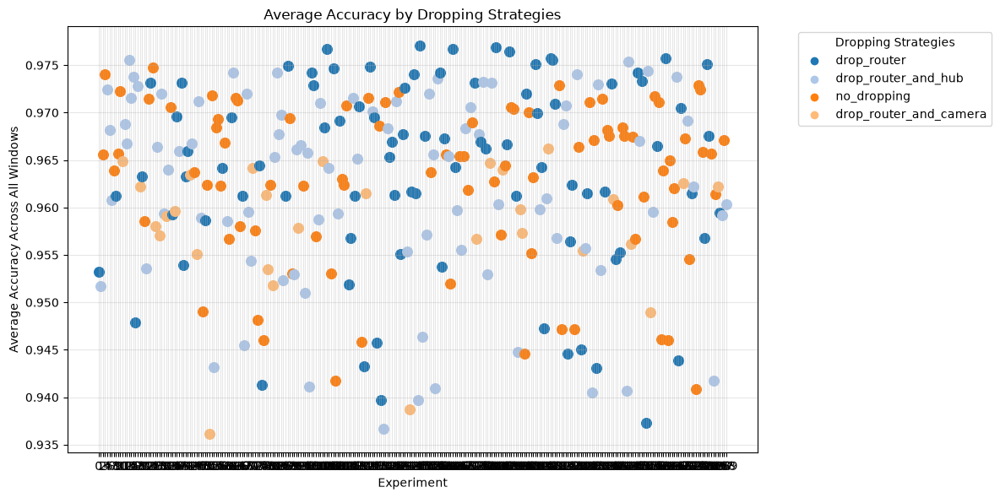

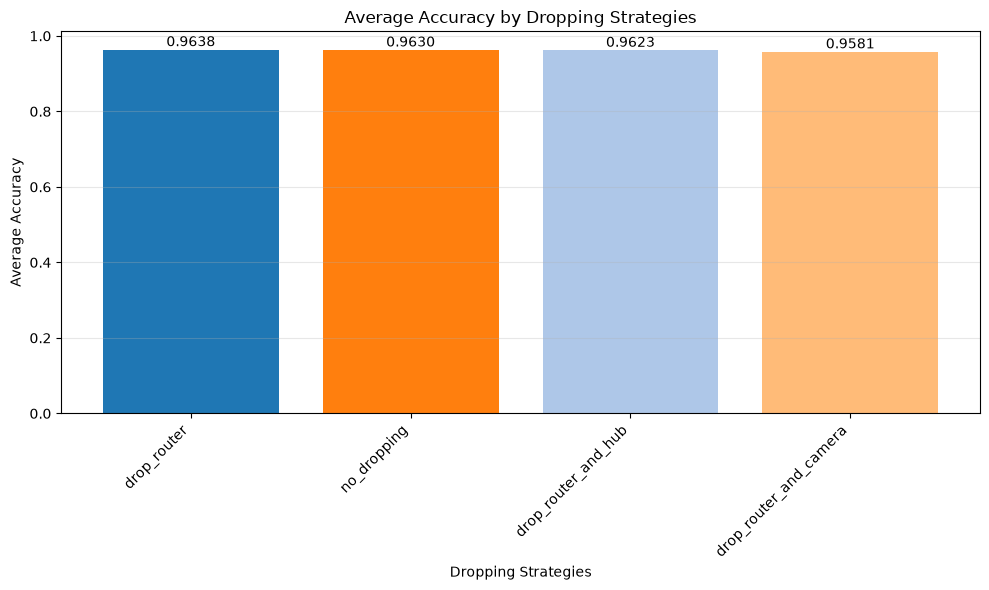

        dropping_strategy  accuracy
0             drop_router  0.963835
3             no_dropping  0.962969
2     drop_router_and_hub  0.962255
1  drop_router_and_camera  0.958075


In [15]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
dropping_strategies = []
accuracies = []

for result in all_perfs.values():
    if len(result["feature_combination"]) <= 4 or result["labeling_strategy"] == "nonIot-vs-iot-vs-iotHealthCare":
        continue
    dropping_strategies.append(result["dropping_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_dropping_strategies = list(dict.fromkeys(dropping_strategies))

color_map = {
    dropping_strategy: plt.cm.tab20(i % 20)
    for i, dropping_strategy in enumerate(unique_dropping_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (dropping_strategy, accuracy) in enumerate(
    zip(dropping_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[dropping_strategy],
        s=70
    )

# Legend
for dropping_strategy in unique_dropping_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[dropping_strategy],
        label=dropping_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Dropping Strategies",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Dropping Strategies
# ==========================================

plot_df = pd.DataFrame({
    "dropping_strategy": dropping_strategies,
    "accuracy": accuracies
})

avg_by_dropping_strategy = (
    plot_df
    .groupby("dropping_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_dropping_strategy["dropping_strategy"],
    avg_by_dropping_strategy["accuracy"],
    color=[
        color_map[dropping_strategy]
        for dropping_strategy in avg_by_dropping_strategy["dropping_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_dropping_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Dropping Strategies")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_dropping_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_dropping_strategy)

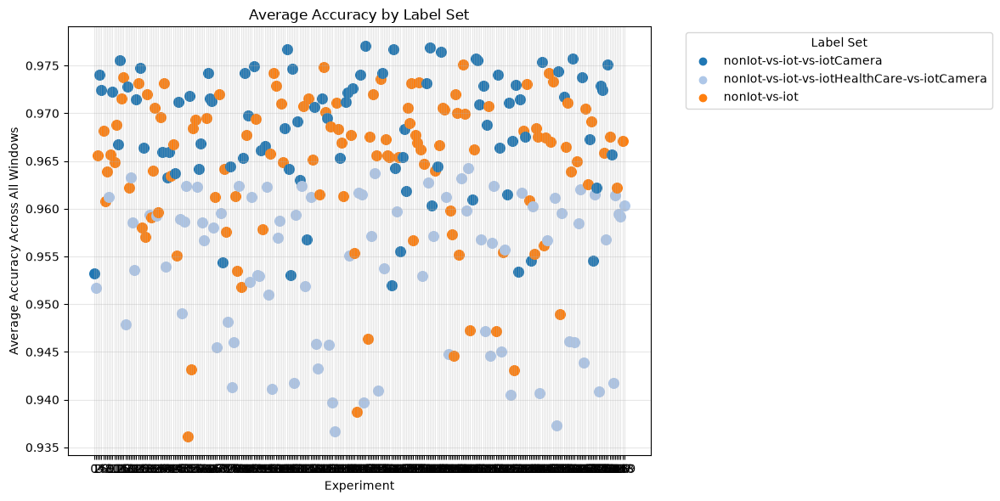

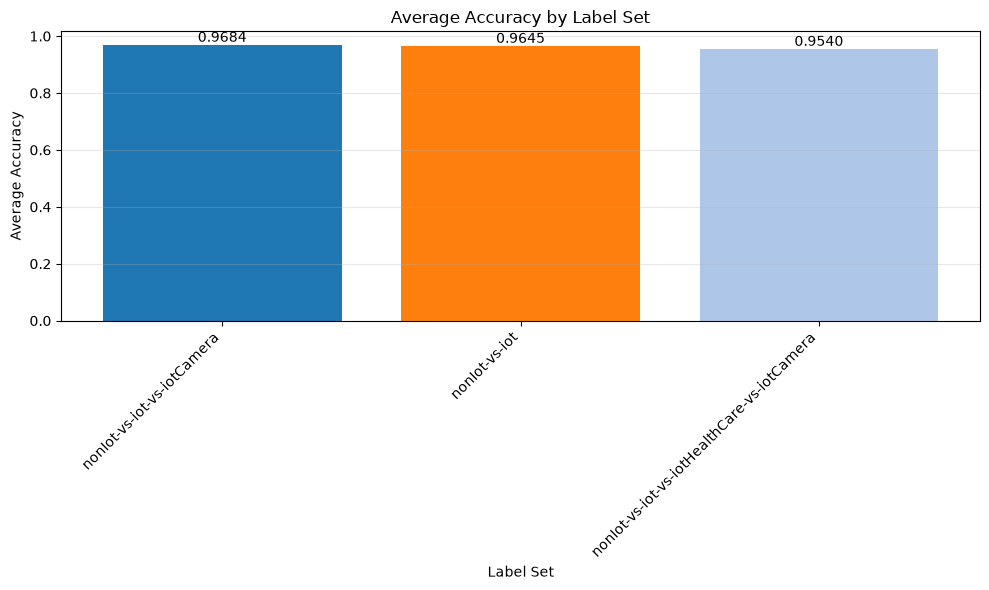

                             labeling_strategy  accuracy
1                   nonIot-vs-iot-vs-iotCamera  0.968403
0                                nonIot-vs-iot  0.964526
2  nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera  0.953979


In [16]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
labeling_strategies = []
accuracies = []

for result in all_perfs.values():
    if len(result["feature_combination"]) <= 4 or result["labeling_strategy"] == "nonIot-vs-iot-vs-iotHealthCare":
        continue
    labeling_strategies.append(result["labeling_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_labeling_strategies = list(dict.fromkeys(labeling_strategies))

color_map = {
    labeling_strategy: plt.cm.tab20(i % 20)
    for i, labeling_strategy in enumerate(unique_labeling_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (labeling_strategy, accuracy) in enumerate(
    zip(labeling_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[labeling_strategy],
        s=70
    )

# Legend
for labeling_strategy in unique_labeling_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[labeling_strategy],
        label=labeling_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Label Set")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Label Set",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Label Set
# ==========================================

plot_df = pd.DataFrame({
    "labeling_strategy": labeling_strategies,
    "accuracy": accuracies
})

avg_by_labeling_strategy = (
    plot_df
    .groupby("labeling_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_labeling_strategy["labeling_strategy"],
    avg_by_labeling_strategy["accuracy"],
    color=[
        color_map[labeling_strategy]
        for labeling_strategy in avg_by_labeling_strategy["labeling_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_labeling_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Label Set")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Label Set")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_labeling_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_labeling_strategy)

- Now the 4 labels doesn't work as expected. Let's drop that
### 4.1 - dropping `nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera`

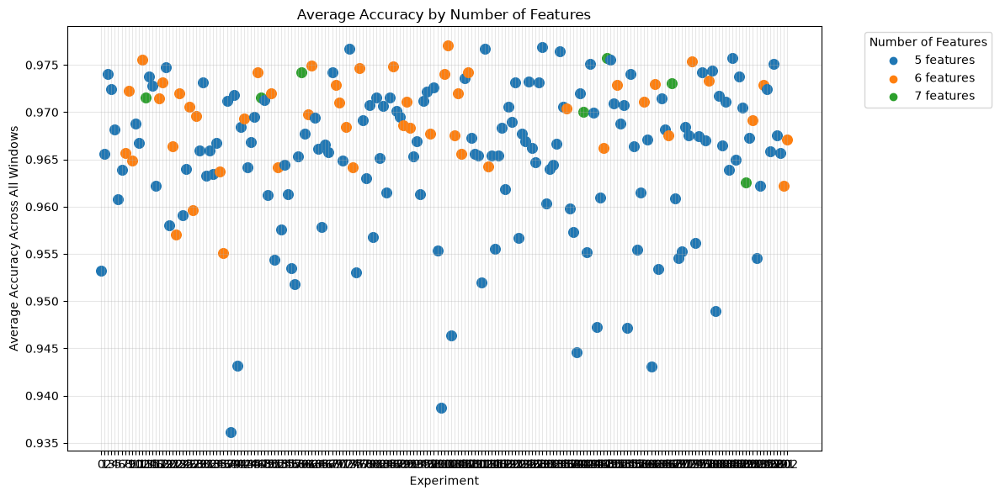

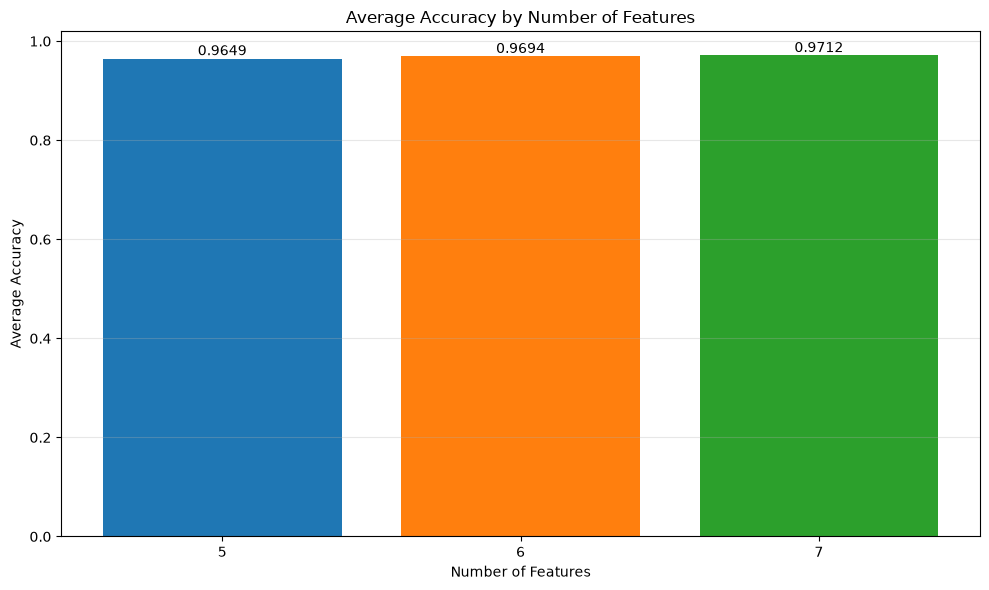

   num_features  accuracy
0             5  0.964886
1             6  0.969373
2             7  0.971231


In [17]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
num_features = []
accuracies = []

for result in all_perfs.values():
    # if result["dropping_strategy"] == "drop_router" and result["labeling_strategy"] == "nonIot-vs-iot":
    if len(result["feature_combination"]) <= 4 or result["labeling_strategy"] in ["nonIot-vs-iot-vs-iotHealthCare", "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera"]:
        continue
    num_features.append(len(result["feature_combination"]))
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each feature count
# --------------------------------
unique_num_features = sorted(set(num_features))

color_map = {
    n: plt.cm.tab10(i % 10)
    for i, n in enumerate(unique_num_features)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (n, accuracy) in enumerate(
    zip(num_features, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[n],
        s=70
    )

# Legend
for n in unique_num_features:
    plt.scatter(
        [],
        [],
        color=color_map[n],
        label=f"{n} features"
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Number of Features")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Number of Features",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy by number of features
# ==========================================

plot_df = pd.DataFrame({
    "num_features": num_features,
    "accuracy": accuracies
})

avg_by_num_features = (
    plot_df
    .groupby("num_features", as_index=False)["accuracy"]
    .mean()
    .sort_values("num_features")
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_num_features["num_features"].astype(str),
    avg_by_num_features["accuracy"],
    color=[
        color_map[n]
        for n in avg_by_num_features["num_features"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_num_features["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Number of Features")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Number of Features")

plt.grid(axis="y", alpha=0.3)

# Leave space for labels above bars
plt.ylim(
    0,
    avg_by_num_features["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Display exact values
print(avg_by_num_features)

- The accuracy for 7 features is even more, however, one of the reason could be that there are less data points for 7 features compared to 6. Nevertheless, 5 features seems to make it worse.

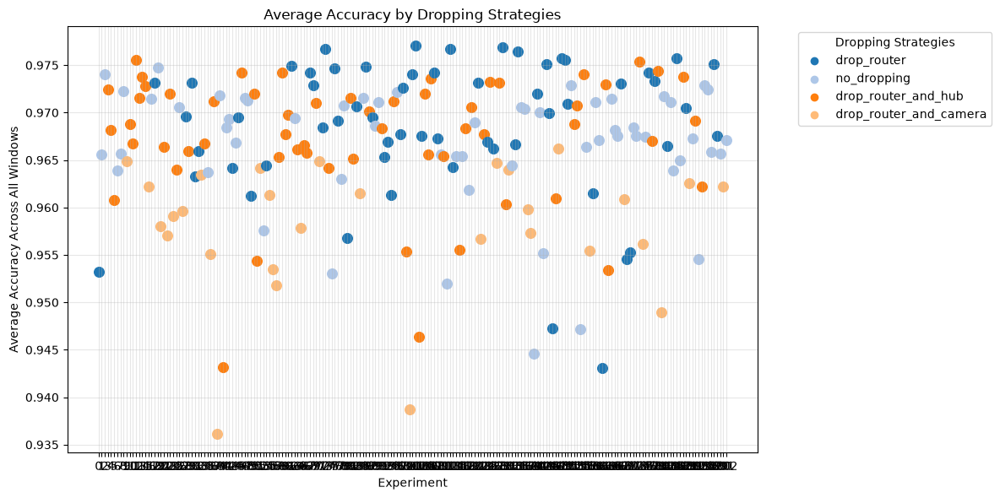

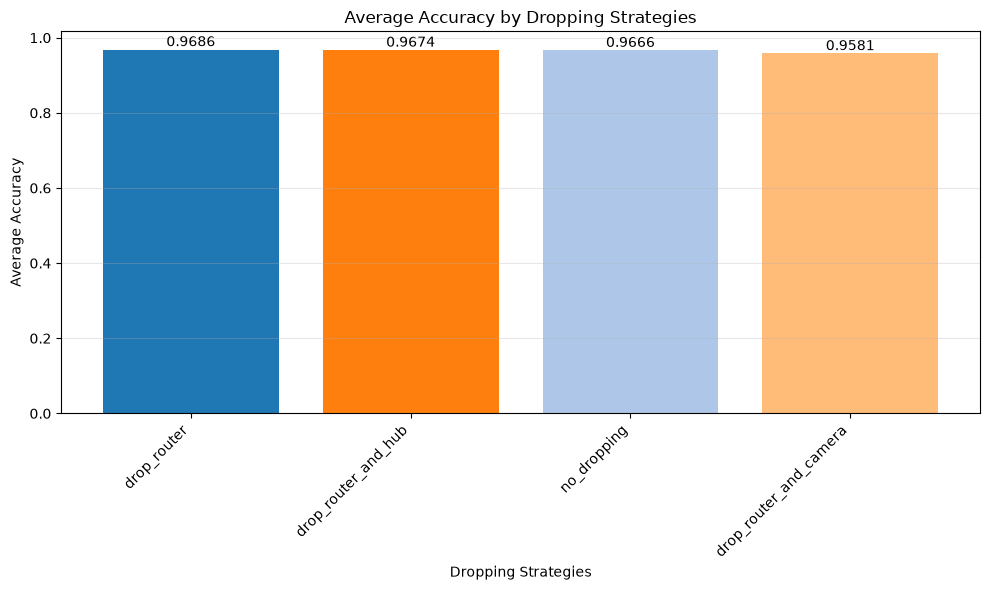

        dropping_strategy  accuracy
0             drop_router  0.968600
2     drop_router_and_hub  0.967371
3             no_dropping  0.966648
1  drop_router_and_camera  0.958075


In [18]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
dropping_strategies = []
accuracies = []

for result in all_perfs.values():
    if len(result["feature_combination"]) <= 4 or result["labeling_strategy"] in ["nonIot-vs-iot-vs-iotHealthCare", "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera"]:
        continue
    dropping_strategies.append(result["dropping_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_dropping_strategies = list(dict.fromkeys(dropping_strategies))

color_map = {
    dropping_strategy: plt.cm.tab20(i % 20)
    for i, dropping_strategy in enumerate(unique_dropping_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (dropping_strategy, accuracy) in enumerate(
    zip(dropping_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[dropping_strategy],
        s=70
    )

# Legend
for dropping_strategy in unique_dropping_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[dropping_strategy],
        label=dropping_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Dropping Strategies",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Dropping Strategies
# ==========================================

plot_df = pd.DataFrame({
    "dropping_strategy": dropping_strategies,
    "accuracy": accuracies
})

avg_by_dropping_strategy = (
    plot_df
    .groupby("dropping_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_dropping_strategy["dropping_strategy"],
    avg_by_dropping_strategy["accuracy"],
    color=[
        color_map[dropping_strategy]
        for dropping_strategy in avg_by_dropping_strategy["dropping_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_dropping_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Dropping Strategies")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_dropping_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_dropping_strategy)

- The gap in the dropping strategies seems to be bigger compared to the number of features. Thus, I'll drop `drop_router_and_camera`
### 5.1 - dropping `drop_router_and_camera`

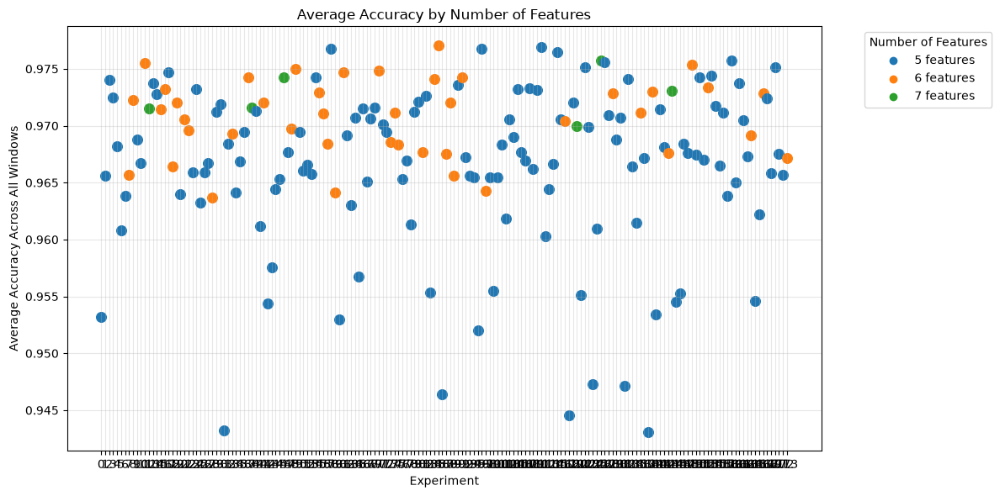

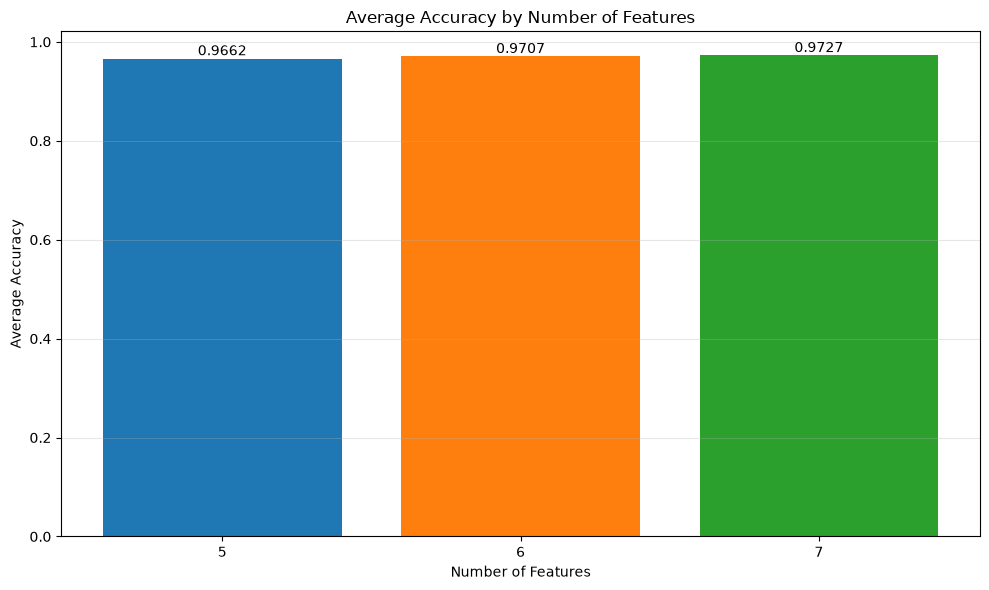

   num_features  accuracy
0             5  0.966237
1             6  0.970715
2             7  0.972679


In [19]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
num_features = []
accuracies = []

for result in all_perfs.values():
    # if result["dropping_strategy"] == "drop_router" and result["labeling_strategy"] == "nonIot-vs-iot":
    if (len(result["feature_combination"]) <= 4 
        or result["labeling_strategy"] in ["nonIot-vs-iot-vs-iotHealthCare", "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera"]
        or result["dropping_strategy"] in ["drop_router_and_camera"]
    ):
        continue
    num_features.append(len(result["feature_combination"]))
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each feature count
# --------------------------------
unique_num_features = sorted(set(num_features))

color_map = {
    n: plt.cm.tab10(i % 10)
    for i, n in enumerate(unique_num_features)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (n, accuracy) in enumerate(
    zip(num_features, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[n],
        s=70
    )

# Legend
for n in unique_num_features:
    plt.scatter(
        [],
        [],
        color=color_map[n],
        label=f"{n} features"
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Number of Features")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Number of Features",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy by number of features
# ==========================================

plot_df = pd.DataFrame({
    "num_features": num_features,
    "accuracy": accuracies
})

avg_by_num_features = (
    plot_df
    .groupby("num_features", as_index=False)["accuracy"]
    .mean()
    .sort_values("num_features")
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_num_features["num_features"].astype(str),
    avg_by_num_features["accuracy"],
    color=[
        color_map[n]
        for n in avg_by_num_features["num_features"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_num_features["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Number of Features")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Number of Features")

plt.grid(axis="y", alpha=0.3)

# Leave space for labels above bars
plt.ylim(
    0,
    avg_by_num_features["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Display exact values
print(avg_by_num_features)

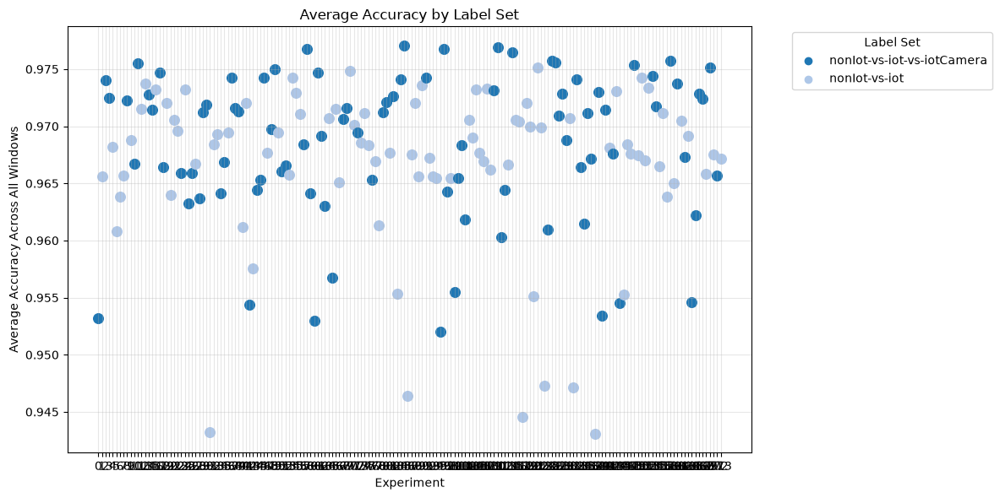

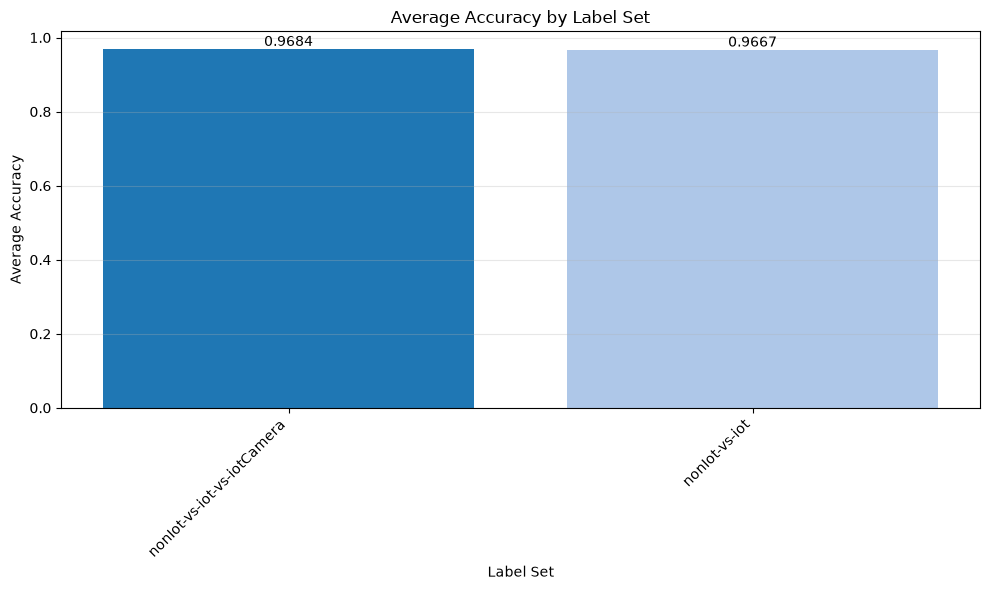

            labeling_strategy  accuracy
1  nonIot-vs-iot-vs-iotCamera  0.968403
0               nonIot-vs-iot  0.966677


In [20]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
labeling_strategies = []
accuracies = []

for result in all_perfs.values():
    if (len(result["feature_combination"]) <= 4 
        or result["labeling_strategy"] in ["nonIot-vs-iot-vs-iotHealthCare", "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera"]
        or result["dropping_strategy"] in ["drop_router_and_camera"]
    ):
        continue
    labeling_strategies.append(result["labeling_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_labeling_strategies = list(dict.fromkeys(labeling_strategies))

color_map = {
    labeling_strategy: plt.cm.tab20(i % 20)
    for i, labeling_strategy in enumerate(unique_labeling_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (labeling_strategy, accuracy) in enumerate(
    zip(labeling_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[labeling_strategy],
        s=70
    )

# Legend
for labeling_strategy in unique_labeling_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[labeling_strategy],
        label=labeling_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Label Set")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Label Set",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Label Set
# ==========================================

plot_df = pd.DataFrame({
    "labeling_strategy": labeling_strategies,
    "accuracy": accuracies
})

avg_by_labeling_strategy = (
    plot_df
    .groupby("labeling_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_labeling_strategy["labeling_strategy"],
    avg_by_labeling_strategy["accuracy"],
    color=[
        color_map[labeling_strategy]
        for labeling_strategy in avg_by_labeling_strategy["labeling_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_labeling_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Label Set")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Label Set")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_labeling_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_labeling_strategy)

- Label set looks the same, 5 features did the worse, let's filter that out
### 6.1 - dropping 5 features

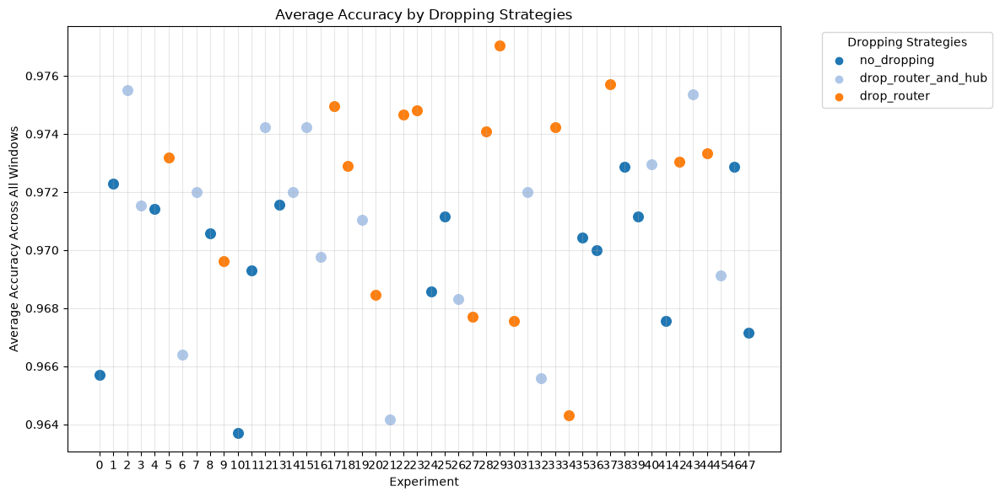

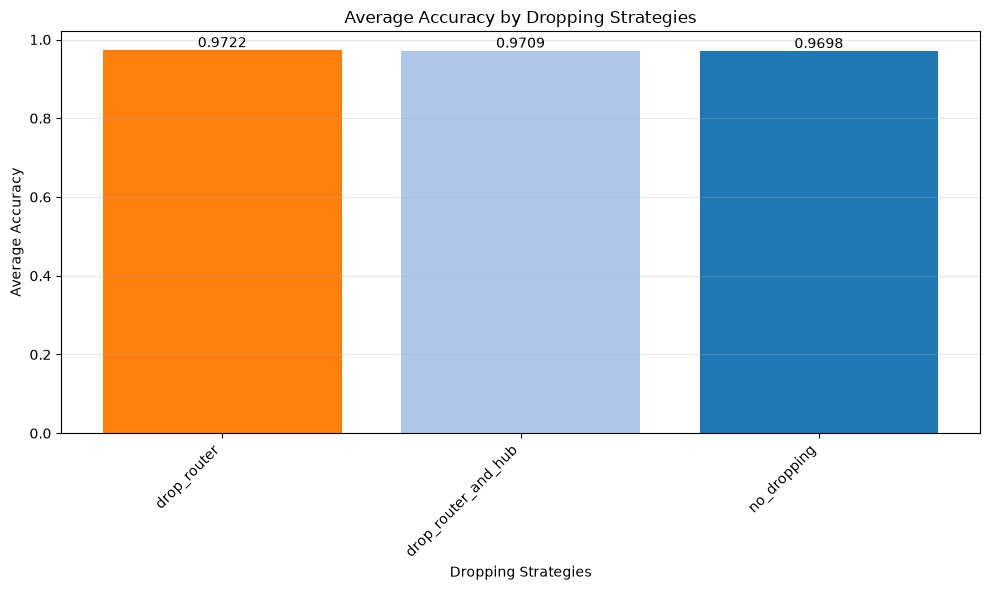

     dropping_strategy  accuracy
0          drop_router  0.972222
1  drop_router_and_hub  0.970890
2          no_dropping  0.969768


In [21]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
dropping_strategies = []
accuracies = []

for result in all_perfs.values():
    if (len(result["feature_combination"]) <= 5 
        or result["labeling_strategy"] in ["nonIot-vs-iot-vs-iotHealthCare", "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera"]
        or result["dropping_strategy"] in ["drop_router_and_camera"]
    ):        
        continue
    dropping_strategies.append(result["dropping_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_dropping_strategies = list(dict.fromkeys(dropping_strategies))

color_map = {
    dropping_strategy: plt.cm.tab20(i % 20)
    for i, dropping_strategy in enumerate(unique_dropping_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (dropping_strategy, accuracy) in enumerate(
    zip(dropping_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[dropping_strategy],
        s=70
    )

# Legend
for dropping_strategy in unique_dropping_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[dropping_strategy],
        label=dropping_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Dropping Strategies",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Dropping Strategies
# ==========================================

plot_df = pd.DataFrame({
    "dropping_strategy": dropping_strategies,
    "accuracy": accuracies
})

avg_by_dropping_strategy = (
    plot_df
    .groupby("dropping_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_dropping_strategy["dropping_strategy"],
    avg_by_dropping_strategy["accuracy"],
    color=[
        color_map[dropping_strategy]
        for dropping_strategy in avg_by_dropping_strategy["dropping_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_dropping_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Dropping Strategies")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_dropping_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_dropping_strategy)

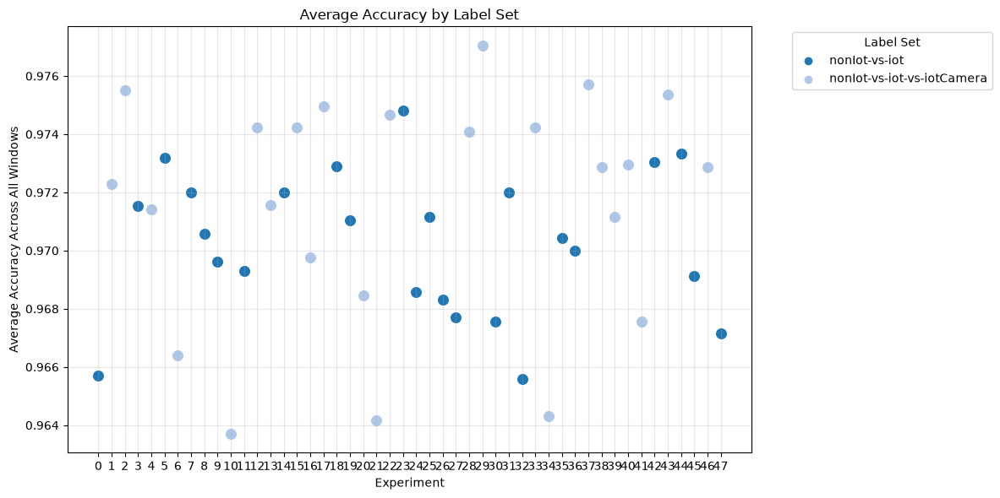

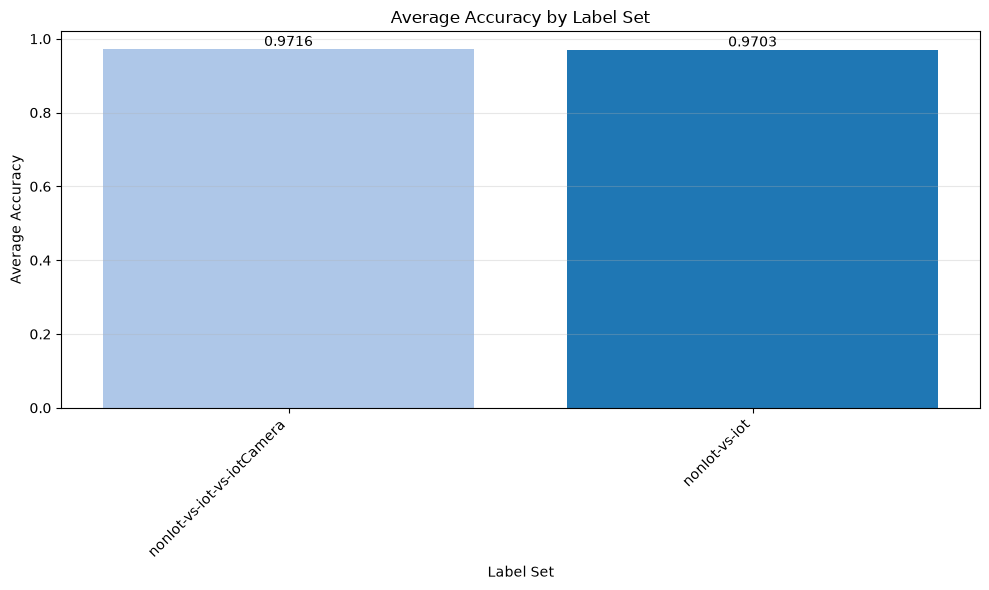

            labeling_strategy  accuracy
1  nonIot-vs-iot-vs-iotCamera  0.971645
0               nonIot-vs-iot  0.970275


In [22]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
labeling_strategies = []
accuracies = []

for result in all_perfs.values():
    if (len(result["feature_combination"]) <= 5 
        or result["labeling_strategy"] in ["nonIot-vs-iot-vs-iotHealthCare", "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera"]
        or result["dropping_strategy"] in ["drop_router_and_camera"]
    ):
        continue
    labeling_strategies.append(result["labeling_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_labeling_strategies = list(dict.fromkeys(labeling_strategies))

color_map = {
    labeling_strategy: plt.cm.tab20(i % 20)
    for i, labeling_strategy in enumerate(unique_labeling_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (labeling_strategy, accuracy) in enumerate(
    zip(labeling_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[labeling_strategy],
        s=70
    )

# Legend
for labeling_strategy in unique_labeling_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[labeling_strategy],
        label=labeling_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Label Set")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Label Set",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Label Set
# ==========================================

plot_df = pd.DataFrame({
    "labeling_strategy": labeling_strategies,
    "accuracy": accuracies
})

avg_by_labeling_strategy = (
    plot_df
    .groupby("labeling_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_labeling_strategy["labeling_strategy"],
    avg_by_labeling_strategy["accuracy"],
    color=[
        color_map[labeling_strategy]
        for labeling_strategy in avg_by_labeling_strategy["labeling_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_labeling_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Label Set")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Label Set")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_labeling_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_labeling_strategy)

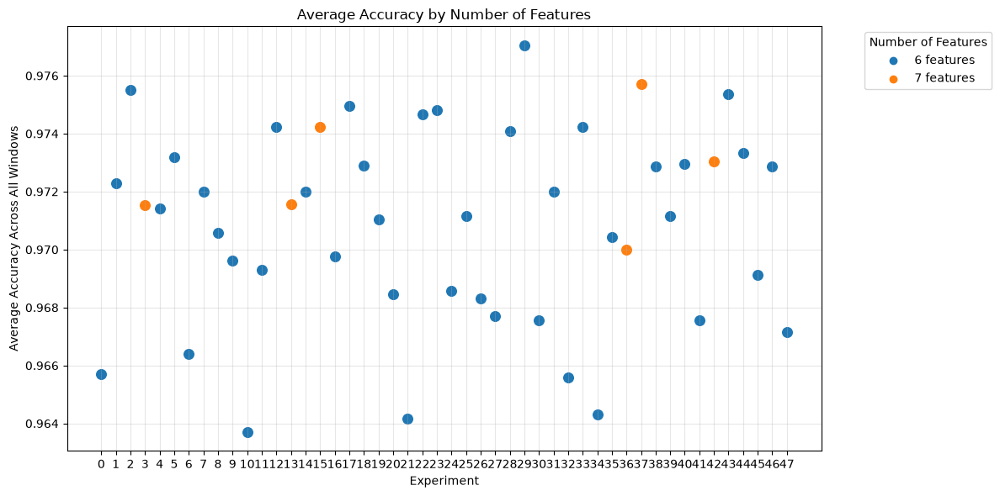

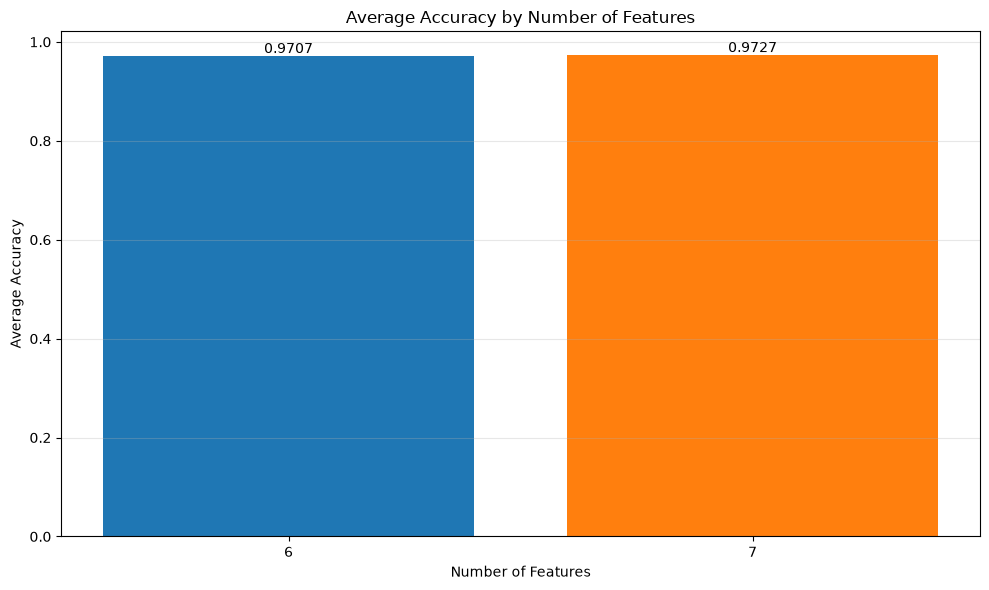

   num_features  accuracy
0             6  0.970715
1             7  0.972679


In [23]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
num_features = []
accuracies = []

for result in all_perfs.values():
    # if result["dropping_strategy"] == "drop_router" and result["labeling_strategy"] == "nonIot-vs-iot":
    if (len(result["feature_combination"]) <= 5 
        or result["labeling_strategy"] in ["nonIot-vs-iot-vs-iotHealthCare", "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera"]
        or result["dropping_strategy"] in ["drop_router_and_camera"]
    ):
        continue
    num_features.append(len(result["feature_combination"]))
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each feature count
# --------------------------------
unique_num_features = sorted(set(num_features))

color_map = {
    n: plt.cm.tab10(i % 10)
    for i, n in enumerate(unique_num_features)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (n, accuracy) in enumerate(
    zip(num_features, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[n],
        s=70
    )

# Legend
for n in unique_num_features:
    plt.scatter(
        [],
        [],
        color=color_map[n],
        label=f"{n} features"
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Number of Features")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Number of Features",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy by number of features
# ==========================================

plot_df = pd.DataFrame({
    "num_features": num_features,
    "accuracy": accuracies
})

avg_by_num_features = (
    plot_df
    .groupby("num_features", as_index=False)["accuracy"]
    .mean()
    .sort_values("num_features")
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_num_features["num_features"].astype(str),
    avg_by_num_features["accuracy"],
    color=[
        color_map[n]
        for n in avg_by_num_features["num_features"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_num_features["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Number of Features")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Number of Features")

plt.grid(axis="y", alpha=0.3)

# Leave space for labels above bars
plt.ylim(
    0,
    avg_by_num_features["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.savefig("imgs/avg-accuracies-by-num-features.png", dpi=300, bbox_inches="tight")
plt.show()


# Display exact values
print(avg_by_num_features)

### Stop 1.1
- Now we have the following optimal parameters:
    - Number of features: `[6, 7]`
    - Label Set: `[nonIot-vs-iot-vs-iotCamera, nonIot-vs-iot]`
    - Drop Set: `[drop_router, drop_router_and_hub, no_dropping]`

## 1.2 - dropping `drop_router_and_camera`

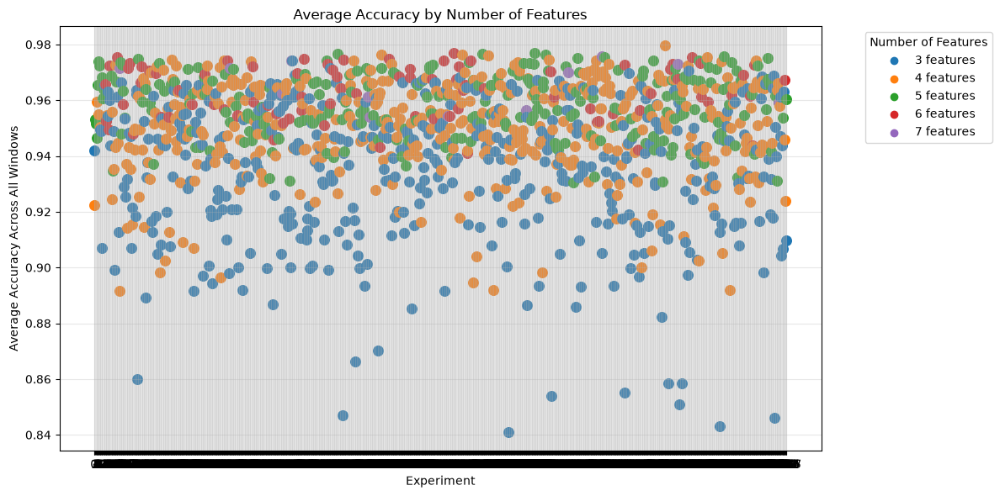

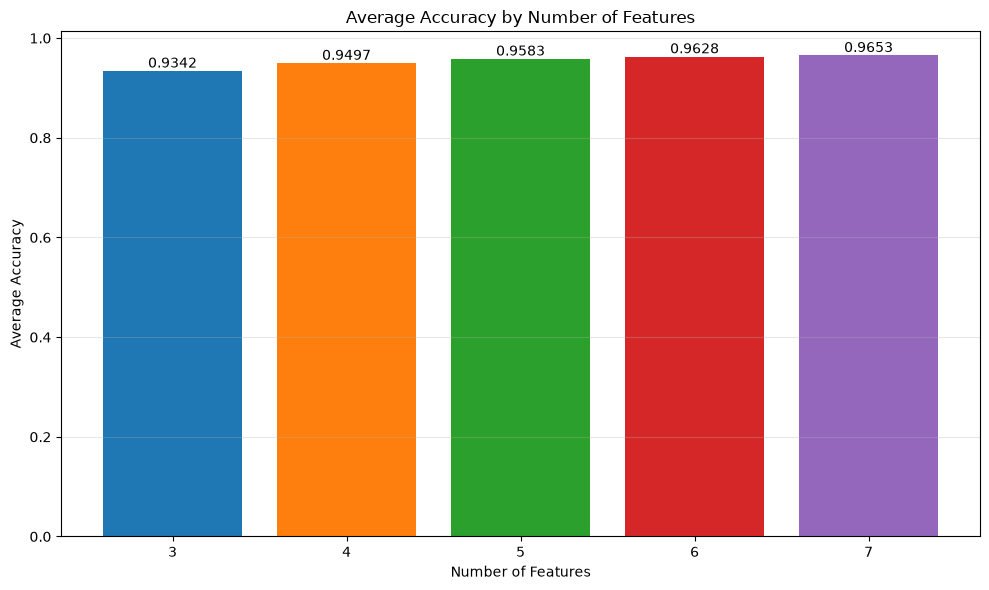

   num_features  accuracy
0             3  0.934202
1             4  0.949694
2             5  0.958256
3             6  0.962833
4             7  0.965309


In [24]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
num_features = []
accuracies = []

for result in all_perfs.values():
    # if result["dropping_strategy"] == "drop_router" and result["labeling_strategy"] == "nonIot-vs-iot":
    if (
        result["dropping_strategy"] in ["drop_router_and_camera"]
    ):
        continue
    num_features.append(len(result["feature_combination"]))
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each feature count
# --------------------------------
unique_num_features = sorted(set(num_features))

color_map = {
    n: plt.cm.tab10(i % 10)
    for i, n in enumerate(unique_num_features)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (n, accuracy) in enumerate(
    zip(num_features, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[n],
        s=70
    )

# Legend
for n in unique_num_features:
    plt.scatter(
        [],
        [],
        color=color_map[n],
        label=f"{n} features"
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Number of Features")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Number of Features",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy by number of features
# ==========================================

plot_df = pd.DataFrame({
    "num_features": num_features,
    "accuracy": accuracies
})

avg_by_num_features = (
    plot_df
    .groupby("num_features", as_index=False)["accuracy"]
    .mean()
    .sort_values("num_features")
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_num_features["num_features"].astype(str),
    avg_by_num_features["accuracy"],
    color=[
        color_map[n]
        for n in avg_by_num_features["num_features"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_num_features["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Number of Features")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Number of Features")

plt.grid(axis="y", alpha=0.3)

# Leave space for labels above bars
plt.ylim(
    0,
    avg_by_num_features["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Display exact values
print(avg_by_num_features)

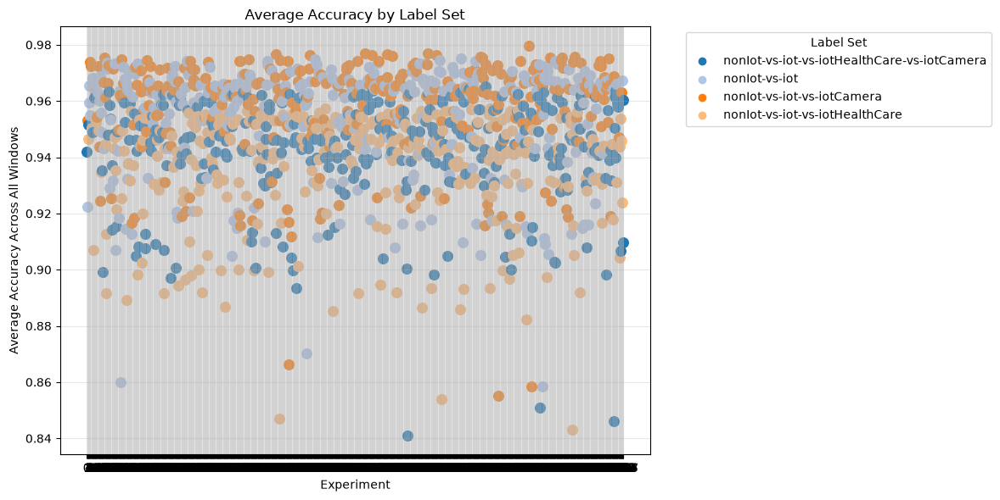

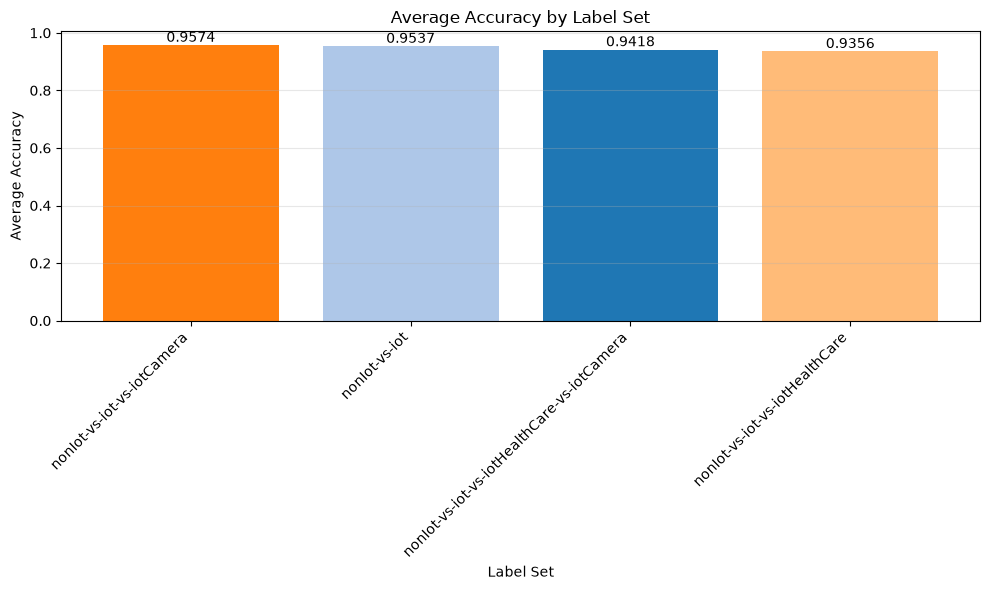

                             labeling_strategy  accuracy
1                   nonIot-vs-iot-vs-iotCamera  0.957362
0                                nonIot-vs-iot  0.953667
3  nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera  0.941844
2               nonIot-vs-iot-vs-iotHealthCare  0.935607


In [25]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
labeling_strategies = []
accuracies = []

for result in all_perfs.values():
    if (
        result["dropping_strategy"] in ["drop_router_and_camera"]
    ):
        continue
    labeling_strategies.append(result["labeling_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_labeling_strategies = list(dict.fromkeys(labeling_strategies))

color_map = {
    labeling_strategy: plt.cm.tab20(i % 20)
    for i, labeling_strategy in enumerate(unique_labeling_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (labeling_strategy, accuracy) in enumerate(
    zip(labeling_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[labeling_strategy],
        s=70
    )

# Legend
for labeling_strategy in unique_labeling_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[labeling_strategy],
        label=labeling_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Label Set")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Label Set",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Label Set
# ==========================================

plot_df = pd.DataFrame({
    "labeling_strategy": labeling_strategies,
    "accuracy": accuracies
})

avg_by_labeling_strategy = (
    plot_df
    .groupby("labeling_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_labeling_strategy["labeling_strategy"],
    avg_by_labeling_strategy["accuracy"],
    color=[
        color_map[labeling_strategy]
        for labeling_strategy in avg_by_labeling_strategy["labeling_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_labeling_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Label Set")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Label Set")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_labeling_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_labeling_strategy)

### 2.2 - dropping `nonIot-vs-iot-vs-iotHealthCare`

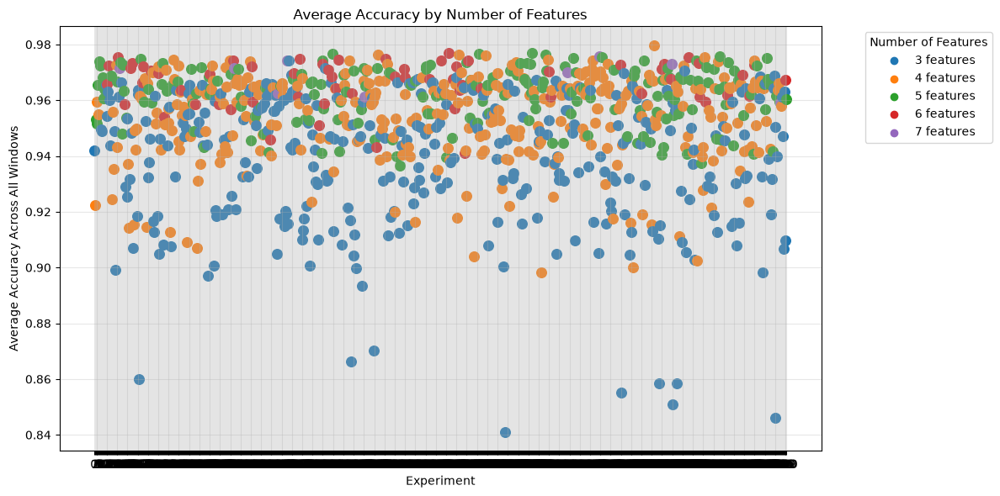

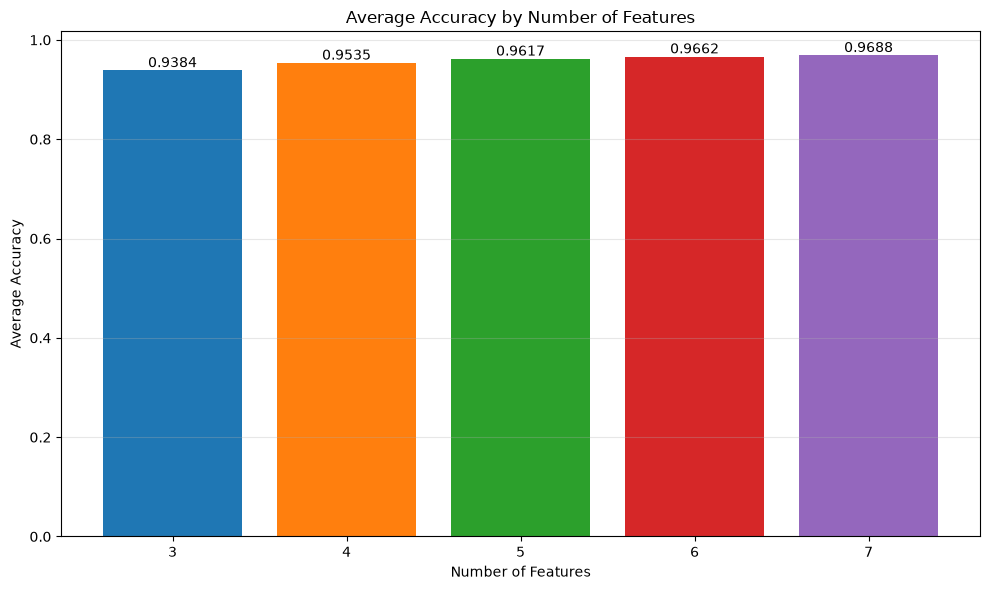

   num_features  accuracy
0             3  0.938411
1             4  0.953509
2             5  0.961699
3             6  0.966160
4             7  0.968765


In [26]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
num_features = []
accuracies = []

for result in all_perfs.values():
    # if result["dropping_strategy"] == "drop_router" and result["labeling_strategy"] == "nonIot-vs-iot":
    if (
        result["dropping_strategy"] in ["drop_router_and_camera"]
        or result["labeling_strategy"] in ["nonIot-vs-iot-vs-iotHealthCare"]
    ):
        continue
    num_features.append(len(result["feature_combination"]))
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each feature count
# --------------------------------
unique_num_features = sorted(set(num_features))

color_map = {
    n: plt.cm.tab10(i % 10)
    for i, n in enumerate(unique_num_features)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (n, accuracy) in enumerate(
    zip(num_features, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[n],
        s=70
    )

# Legend
for n in unique_num_features:
    plt.scatter(
        [],
        [],
        color=color_map[n],
        label=f"{n} features"
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Number of Features")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Number of Features",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy by number of features
# ==========================================

plot_df = pd.DataFrame({
    "num_features": num_features,
    "accuracy": accuracies
})

avg_by_num_features = (
    plot_df
    .groupby("num_features", as_index=False)["accuracy"]
    .mean()
    .sort_values("num_features")
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_num_features["num_features"].astype(str),
    avg_by_num_features["accuracy"],
    color=[
        color_map[n]
        for n in avg_by_num_features["num_features"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_num_features["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Number of Features")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Number of Features")

plt.grid(axis="y", alpha=0.3)

# Leave space for labels above bars
plt.ylim(
    0,
    avg_by_num_features["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Display exact values
print(avg_by_num_features)

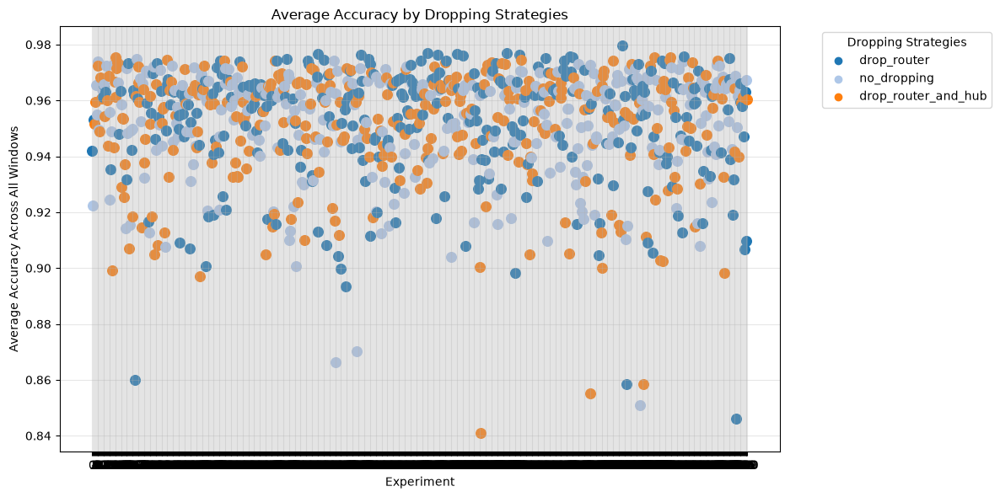

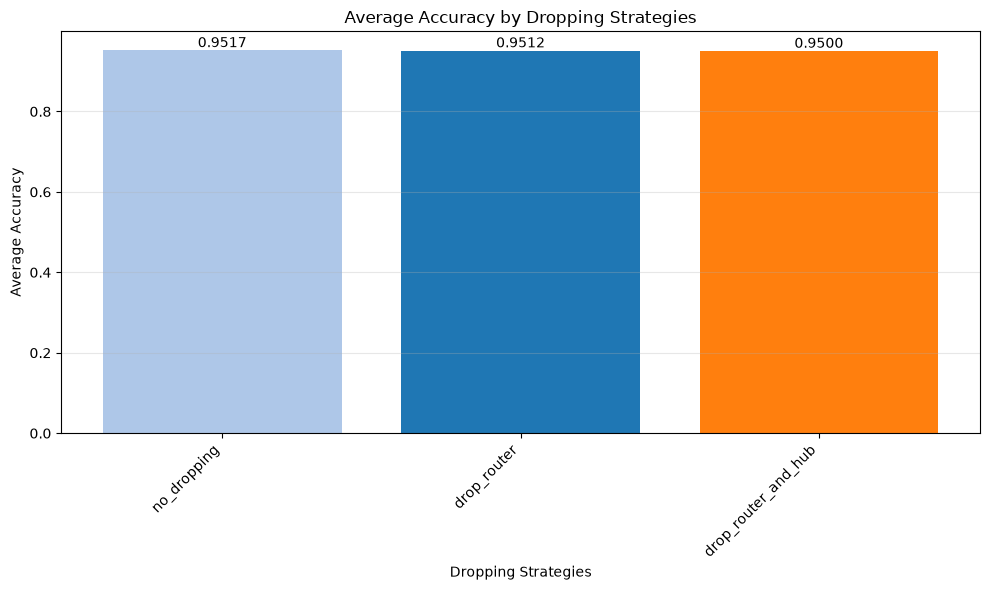

     dropping_strategy  accuracy
2          no_dropping  0.951658
0          drop_router  0.951169
1  drop_router_and_hub  0.950046


In [27]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
dropping_strategies = []
accuracies = []

for result in all_perfs.values():
    if (
        result["dropping_strategy"] in ["drop_router_and_camera"]
        or result["labeling_strategy"] in ["nonIot-vs-iot-vs-iotHealthCare"]
    ):
        continue
    dropping_strategies.append(result["dropping_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_dropping_strategies = list(dict.fromkeys(dropping_strategies))

color_map = {
    dropping_strategy: plt.cm.tab20(i % 20)
    for i, dropping_strategy in enumerate(unique_dropping_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (dropping_strategy, accuracy) in enumerate(
    zip(dropping_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[dropping_strategy],
        s=70
    )

# Legend
for dropping_strategy in unique_dropping_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[dropping_strategy],
        label=dropping_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Dropping Strategies",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Dropping Strategies
# ==========================================

plot_df = pd.DataFrame({
    "dropping_strategy": dropping_strategies,
    "accuracy": accuracies
})

avg_by_dropping_strategy = (
    plot_df
    .groupby("dropping_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_dropping_strategy["dropping_strategy"],
    avg_by_dropping_strategy["accuracy"],
    color=[
        color_map[dropping_strategy]
        for dropping_strategy in avg_by_dropping_strategy["dropping_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_dropping_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Dropping Strategies")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_dropping_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_dropping_strategy)

### 3.2 - dropping 3 features

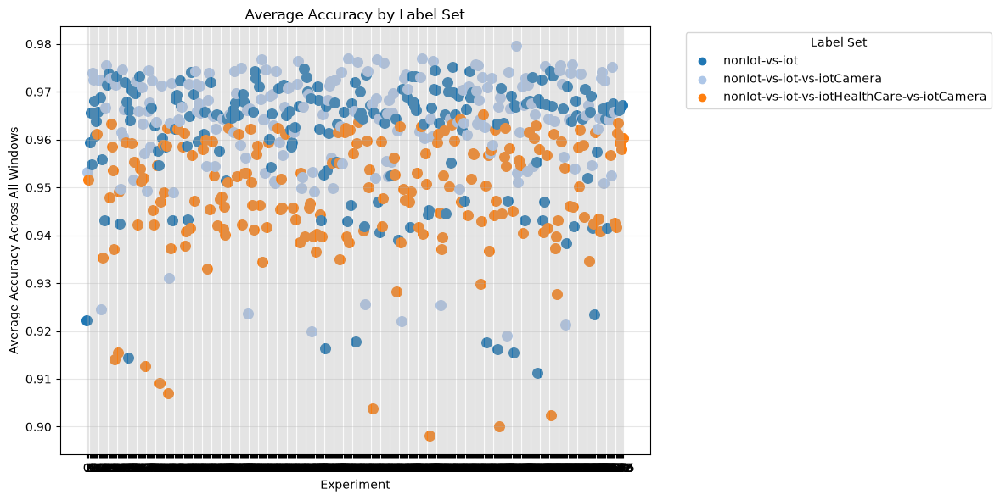

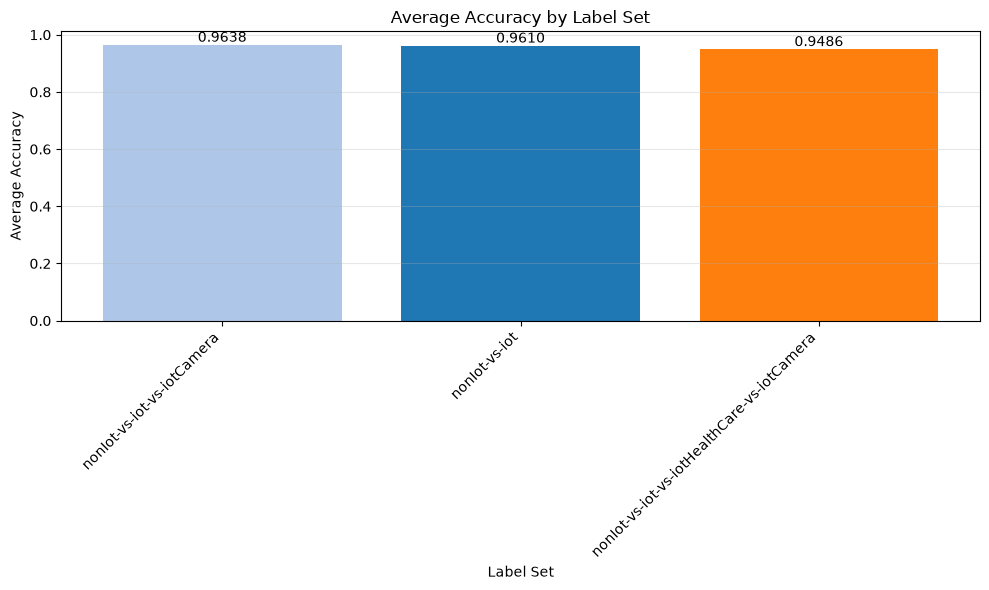

                             labeling_strategy  accuracy
1                   nonIot-vs-iot-vs-iotCamera  0.963783
0                                nonIot-vs-iot  0.961038
2  nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera  0.948635


In [28]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
labeling_strategies = []
accuracies = []

for result in all_perfs.values():
    if (
        result["dropping_strategy"] in ["drop_router_and_camera"]
        or result["labeling_strategy"] in ["nonIot-vs-iot-vs-iotHealthCare"]
        or len(result["feature_combination"]) <= 3
    ):
        continue
    labeling_strategies.append(result["labeling_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_labeling_strategies = list(dict.fromkeys(labeling_strategies))

color_map = {
    labeling_strategy: plt.cm.tab20(i % 20)
    for i, labeling_strategy in enumerate(unique_labeling_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (labeling_strategy, accuracy) in enumerate(
    zip(labeling_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[labeling_strategy],
        s=70
    )

# Legend
for labeling_strategy in unique_labeling_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[labeling_strategy],
        label=labeling_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Label Set")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Label Set",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Label Set
# ==========================================

plot_df = pd.DataFrame({
    "labeling_strategy": labeling_strategies,
    "accuracy": accuracies
})

avg_by_labeling_strategy = (
    plot_df
    .groupby("labeling_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_labeling_strategy["labeling_strategy"],
    avg_by_labeling_strategy["accuracy"],
    color=[
        color_map[labeling_strategy]
        for labeling_strategy in avg_by_labeling_strategy["labeling_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_labeling_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Label Set")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Label Set")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_labeling_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_labeling_strategy)

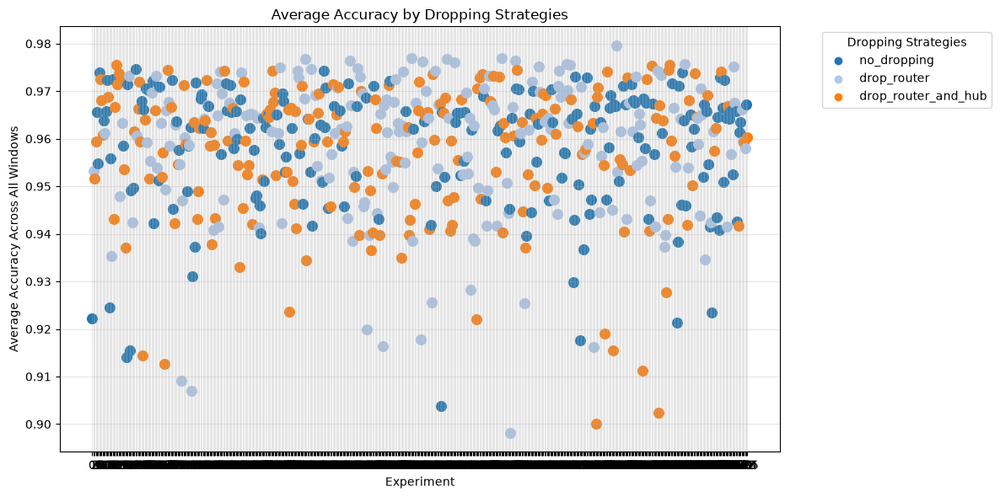

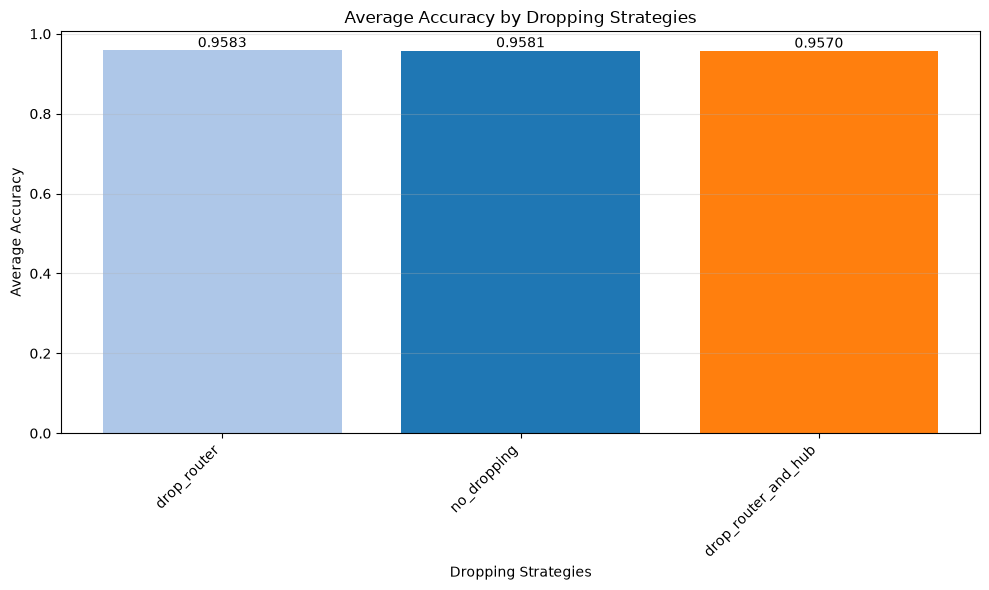

     dropping_strategy  accuracy
0          drop_router  0.958289
2          no_dropping  0.958146
1  drop_router_and_hub  0.957022


In [29]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
dropping_strategies = []
accuracies = []

for result in all_perfs.values():
    if (
        result["dropping_strategy"] in ["drop_router_and_camera"]
        or result["labeling_strategy"] in ["nonIot-vs-iot-vs-iotHealthCare"]
        or len(result["feature_combination"]) <= 3
    ):
        continue
    dropping_strategies.append(result["dropping_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_dropping_strategies = list(dict.fromkeys(dropping_strategies))

color_map = {
    dropping_strategy: plt.cm.tab20(i % 20)
    for i, dropping_strategy in enumerate(unique_dropping_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (dropping_strategy, accuracy) in enumerate(
    zip(dropping_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[dropping_strategy],
        s=70
    )

# Legend
for dropping_strategy in unique_dropping_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[dropping_strategy],
        label=dropping_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Dropping Strategies",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Dropping Strategies
# ==========================================

plot_df = pd.DataFrame({
    "dropping_strategy": dropping_strategies,
    "accuracy": accuracies
})

avg_by_dropping_strategy = (
    plot_df
    .groupby("dropping_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_dropping_strategy["dropping_strategy"],
    avg_by_dropping_strategy["accuracy"],
    color=[
        color_map[dropping_strategy]
        for dropping_strategy in avg_by_dropping_strategy["dropping_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_dropping_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Dropping Strategies")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_dropping_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_dropping_strategy)

### 4.2 - dropping `nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera`

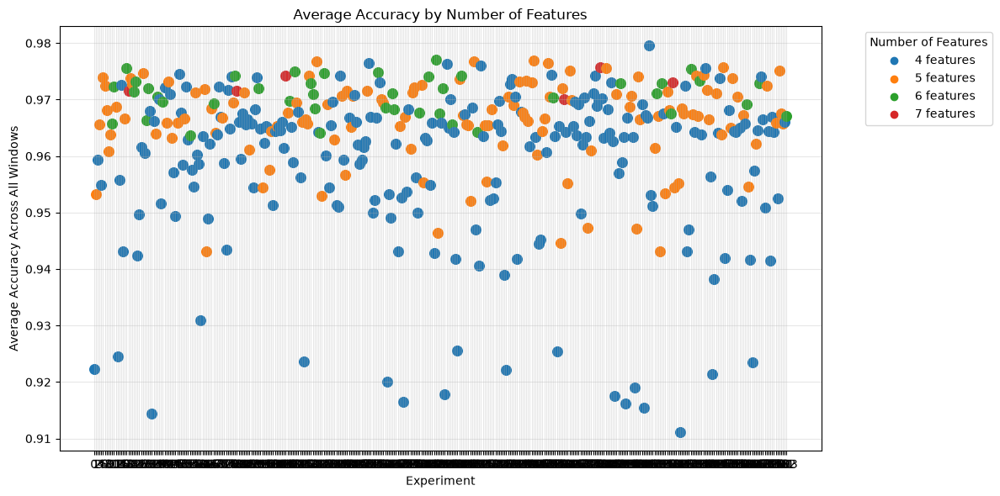

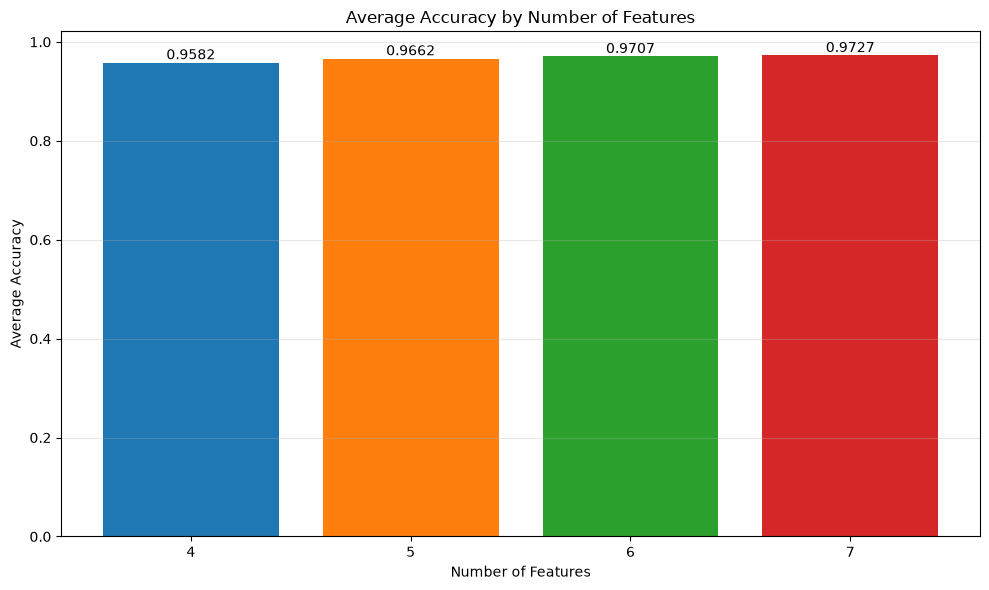

   num_features  accuracy
0             4  0.958161
1             5  0.966237
2             6  0.970715
3             7  0.972679


In [30]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
num_features = []
accuracies = []

for result in all_perfs.values():
    # if result["dropping_strategy"] == "drop_router" and result["labeling_strategy"] == "nonIot-vs-iot":
    if (
        result["dropping_strategy"] in ["drop_router_and_camera"]
        or result["labeling_strategy"] in ["nonIot-vs-iot-vs-iotHealthCare", "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera"]
        or len(result["feature_combination"]) <= 3
    ):
        continue
    num_features.append(len(result["feature_combination"]))
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each feature count
# --------------------------------
unique_num_features = sorted(set(num_features))

color_map = {
    n: plt.cm.tab10(i % 10)
    for i, n in enumerate(unique_num_features)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (n, accuracy) in enumerate(
    zip(num_features, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[n],
        s=70
    )

# Legend
for n in unique_num_features:
    plt.scatter(
        [],
        [],
        color=color_map[n],
        label=f"{n} features"
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Number of Features")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Number of Features",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy by number of features
# ==========================================

plot_df = pd.DataFrame({
    "num_features": num_features,
    "accuracy": accuracies
})

avg_by_num_features = (
    plot_df
    .groupby("num_features", as_index=False)["accuracy"]
    .mean()
    .sort_values("num_features")
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_num_features["num_features"].astype(str),
    avg_by_num_features["accuracy"],
    color=[
        color_map[n]
        for n in avg_by_num_features["num_features"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_num_features["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Number of Features")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Number of Features")

plt.grid(axis="y", alpha=0.3)

# Leave space for labels above bars
plt.ylim(
    0,
    avg_by_num_features["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Display exact values
print(avg_by_num_features)

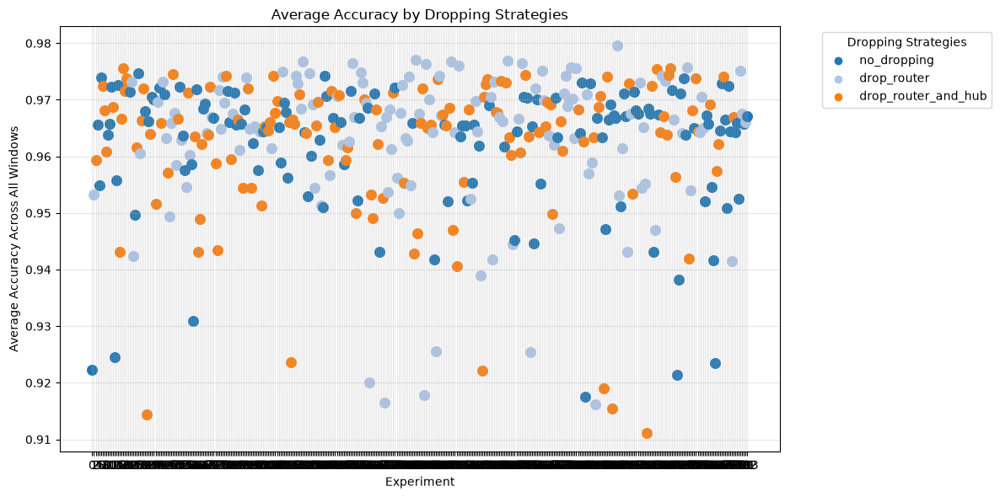

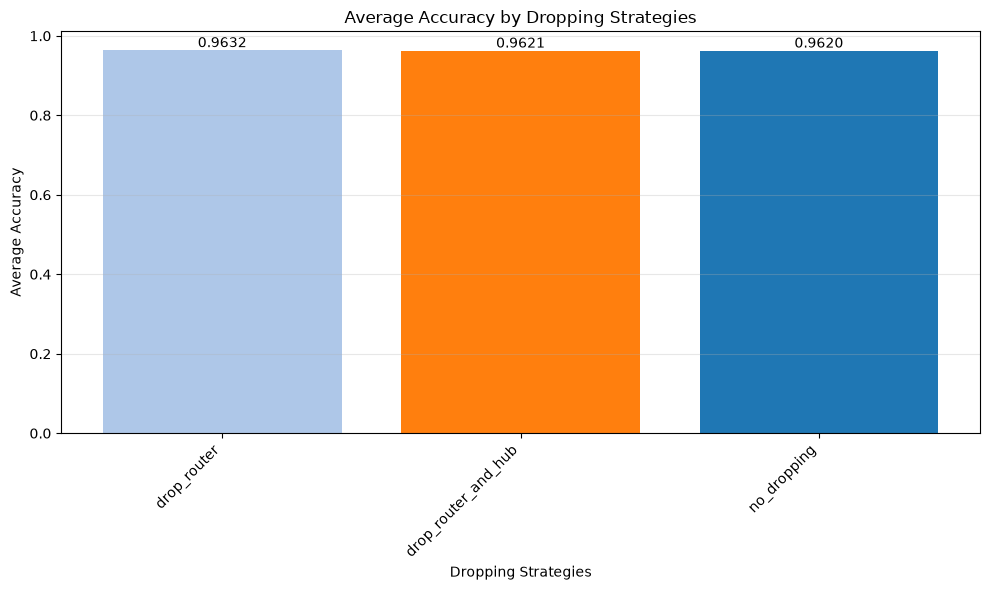

     dropping_strategy  accuracy
0          drop_router  0.963159
1  drop_router_and_hub  0.962090
2          no_dropping  0.961983


In [31]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
dropping_strategies = []
accuracies = []

for result in all_perfs.values():
    if (
        result["dropping_strategy"] in ["drop_router_and_camera"]
        or result["labeling_strategy"] in ["nonIot-vs-iot-vs-iotHealthCare", "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera"]
        or len(result["feature_combination"]) <= 3
    ):
        continue
    dropping_strategies.append(result["dropping_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_dropping_strategies = list(dict.fromkeys(dropping_strategies))

color_map = {
    dropping_strategy: plt.cm.tab20(i % 20)
    for i, dropping_strategy in enumerate(unique_dropping_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (dropping_strategy, accuracy) in enumerate(
    zip(dropping_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[dropping_strategy],
        s=70
    )

# Legend
for dropping_strategy in unique_dropping_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[dropping_strategy],
        label=dropping_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Dropping Strategies",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Dropping Strategies
# ==========================================

plot_df = pd.DataFrame({
    "dropping_strategy": dropping_strategies,
    "accuracy": accuracies
})

avg_by_dropping_strategy = (
    plot_df
    .groupby("dropping_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_dropping_strategy["dropping_strategy"],
    avg_by_dropping_strategy["accuracy"],
    color=[
        color_map[dropping_strategy]
        for dropping_strategy in avg_by_dropping_strategy["dropping_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_dropping_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Dropping Strategies")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_dropping_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_dropping_strategy)

### 5.2 - dropping 4 features
- By step 5, this resemble the first combination. Therefore, we should stop here

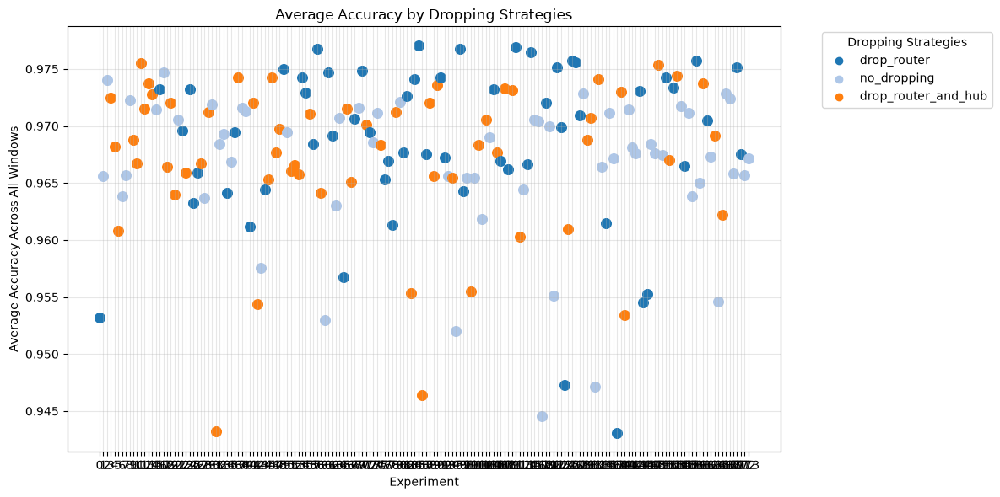

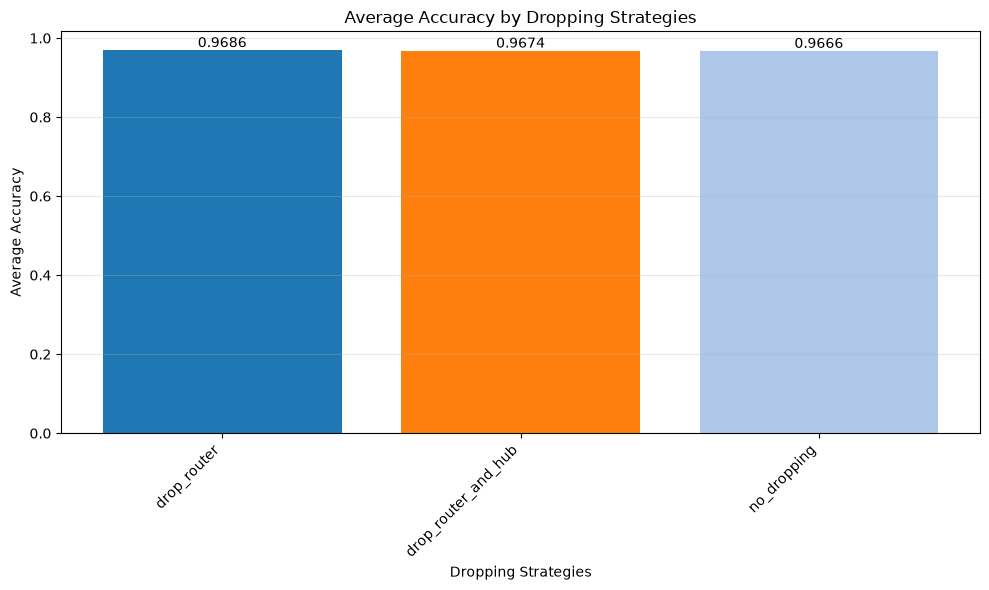

     dropping_strategy  accuracy
0          drop_router  0.968600
1  drop_router_and_hub  0.967371
2          no_dropping  0.966648


In [32]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
dropping_strategies = []
accuracies = []

for result in all_perfs.values():
    if (
        result["dropping_strategy"] in ["drop_router_and_camera"]
        or result["labeling_strategy"] in ["nonIot-vs-iot-vs-iotHealthCare", "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera"]
        or len(result["feature_combination"]) <= 4
    ):
        continue
    dropping_strategies.append(result["dropping_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_dropping_strategies = list(dict.fromkeys(dropping_strategies))

color_map = {
    dropping_strategy: plt.cm.tab20(i % 20)
    for i, dropping_strategy in enumerate(unique_dropping_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (dropping_strategy, accuracy) in enumerate(
    zip(dropping_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[dropping_strategy],
        s=70
    )

# Legend
for dropping_strategy in unique_dropping_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[dropping_strategy],
        label=dropping_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Dropping Strategies",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Dropping Strategies
# ==========================================

plot_df = pd.DataFrame({
    "dropping_strategy": dropping_strategies,
    "accuracy": accuracies
})

avg_by_dropping_strategy = (
    plot_df
    .groupby("dropping_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_dropping_strategy["dropping_strategy"],
    avg_by_dropping_strategy["accuracy"],
    color=[
        color_map[dropping_strategy]
        for dropping_strategy in avg_by_dropping_strategy["dropping_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_dropping_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Dropping Strategies")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Dropping Strategies")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_dropping_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_dropping_strategy)

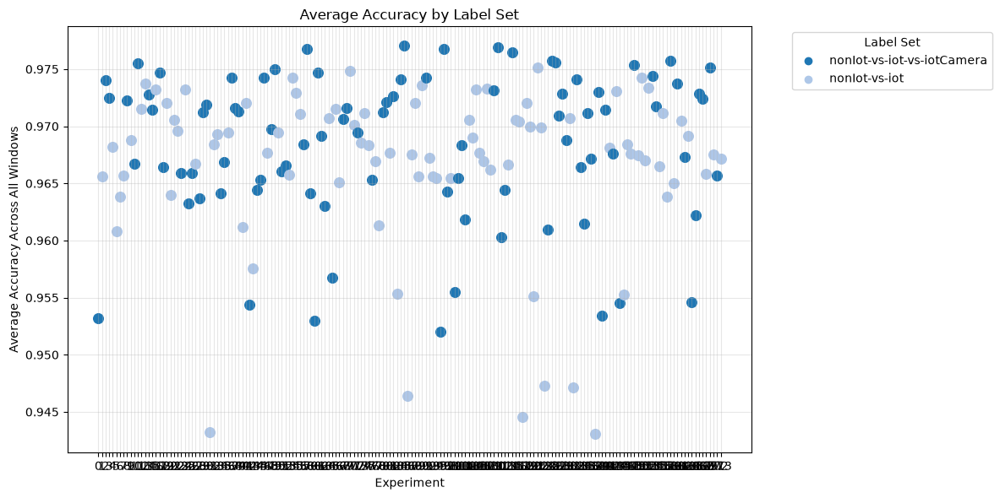

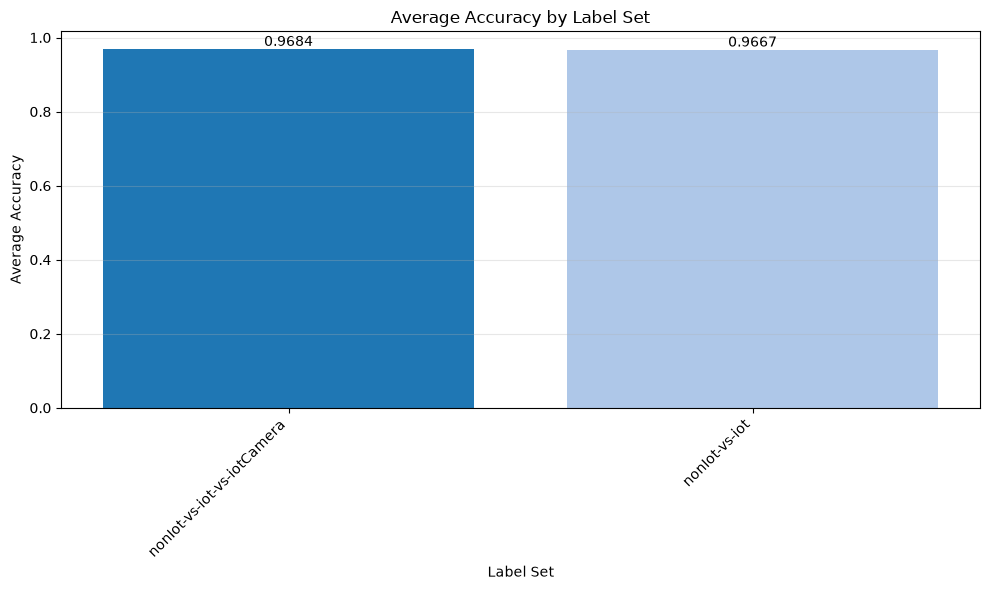

            labeling_strategy  accuracy
1  nonIot-vs-iot-vs-iotCamera  0.968403
0               nonIot-vs-iot  0.966677


In [33]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
labeling_strategies = []
accuracies = []

for result in all_perfs.values():
    if (
        result["dropping_strategy"] in ["drop_router_and_camera"]
        or result["labeling_strategy"] in ["nonIot-vs-iot-vs-iotHealthCare", "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera"]
        or len(result["feature_combination"]) <= 4
    ):
        continue
    labeling_strategies.append(result["labeling_strategy"])
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each Label Set
# --------------------------------
unique_labeling_strategies = list(dict.fromkeys(labeling_strategies))

color_map = {
    labeling_strategy: plt.cm.tab20(i % 20)
    for i, labeling_strategy in enumerate(unique_labeling_strategies)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (labeling_strategy, accuracy) in enumerate(
    zip(labeling_strategies, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[labeling_strategy],
        s=70
    )

# Legend
for labeling_strategy in unique_labeling_strategies:
    plt.scatter(
        [],
        [],
        color=color_map[labeling_strategy],
        label=labeling_strategy
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Label Set")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Label Set",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy per Label Set
# ==========================================

plot_df = pd.DataFrame({
    "labeling_strategy": labeling_strategies,
    "accuracy": accuracies
})

avg_by_labeling_strategy = (
    plot_df
    .groupby("labeling_strategy", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy", ascending=False)
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_labeling_strategy["labeling_strategy"],
    avg_by_labeling_strategy["accuracy"],
    color=[
        color_map[labeling_strategy]
        for labeling_strategy in avg_by_labeling_strategy["labeling_strategy"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_labeling_strategy["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Label Set")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Label Set")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

# Give labels some room above the bars
plt.ylim(
    0,
    avg_by_labeling_strategy["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Optional: display exact values
print(avg_by_labeling_strategy)

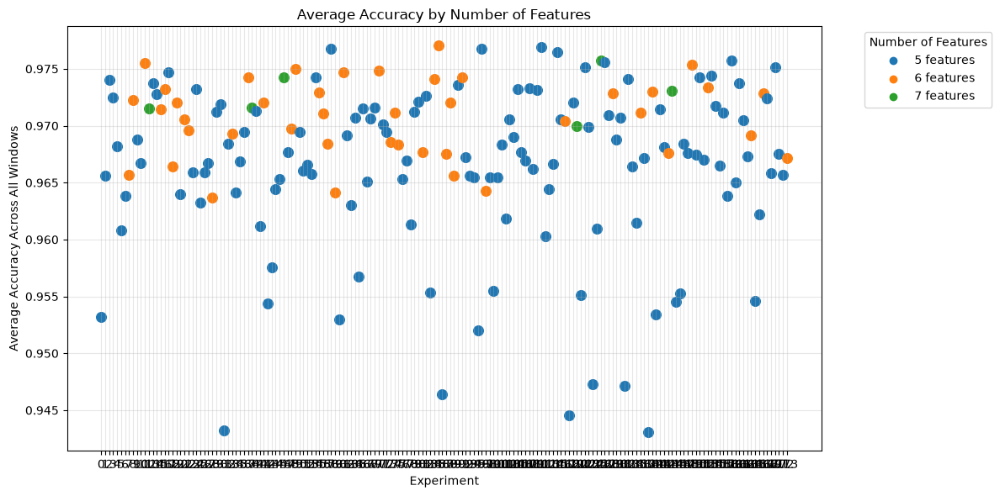

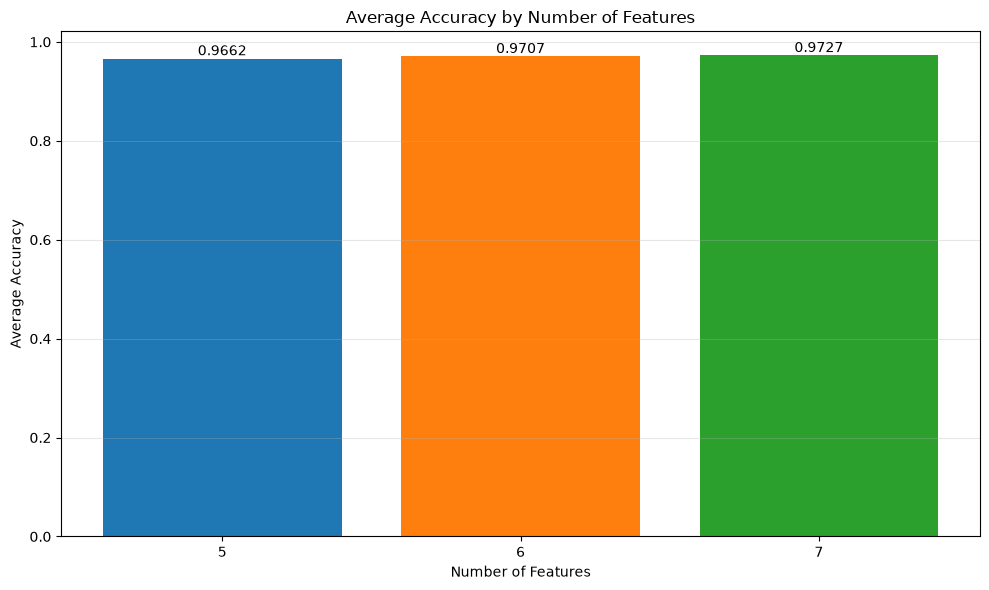

   num_features  accuracy
0             5  0.966237
1             6  0.970715
2             7  0.972679


In [34]:

# --------------------------------
# Extract data from all_perfs
# --------------------------------
num_features = []
accuracies = []

for result in all_perfs.values():
    # if result["dropping_strategy"] == "drop_router" and result["labeling_strategy"] == "nonIot-vs-iot":
    if (
        result["dropping_strategy"] in ["drop_router_and_camera"]
        or result["labeling_strategy"] in ["nonIot-vs-iot-vs-iotHealthCare", "nonIot-vs-iot-vs-iotHealthCare-vs-iotCamera"]
        or len(result["feature_combination"]) <= 4
    ):
        continue
    num_features.append(len(result["feature_combination"]))
    accuracies.append(result["average_across_all_windows"])


# --------------------------------
# Assign color to each feature count
# --------------------------------
unique_num_features = sorted(set(num_features))

color_map = {
    n: plt.cm.tab10(i % 10)
    for i, n in enumerate(unique_num_features)
}


# ==========================================
# Plot 1: All individual experiment results
# ==========================================
plt.figure(figsize=(12, 6))

for i, (n, accuracy) in enumerate(
    zip(num_features, accuracies)
):
    plt.scatter(
        i,
        accuracy,
        color=color_map[n],
        s=70
    )

# Legend
for n in unique_num_features:
    plt.scatter(
        [],
        [],
        color=color_map[n],
        label=f"{n} features"
    )

plt.xlabel("Experiment")
plt.ylabel("Average Accuracy Across All Windows")
plt.title("Average Accuracy by Number of Features")

plt.xticks(range(len(accuracies)))
plt.grid(alpha=0.3)

plt.legend(
    title="Number of Features",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ==========================================
# Plot 2: Average accuracy by number of features
# ==========================================

plot_df = pd.DataFrame({
    "num_features": num_features,
    "accuracy": accuracies
})

avg_by_num_features = (
    plot_df
    .groupby("num_features", as_index=False)["accuracy"]
    .mean()
    .sort_values("num_features")
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    avg_by_num_features["num_features"].astype(str),
    avg_by_num_features["accuracy"],
    color=[
        color_map[n]
        for n in avg_by_num_features["num_features"]
    ]
)

# Add accuracy value above each bar
for bar, accuracy in zip(
    bars,
    avg_by_num_features["accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.4f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Number of Features")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy by Number of Features")

plt.grid(axis="y", alpha=0.3)

# Leave space for labels above bars
plt.ylim(
    0,
    avg_by_num_features["accuracy"].max() * 1.05
)

plt.tight_layout()
plt.show()


# Display exact values
print(avg_by_num_features)

## Result of filtering assignment
- Looks like we reach the same set of optimal parameters for both experiment which are:
    - Number of features: `[6, 7]`
    - Label Set: `[nonIot-vs-iot-vs-iotCamera, nonIot-vs-iot]`
    - Drop Set: `[drop_router, drop_router_and_hub, no_dropping]`